In [ ]:
import torch
import numpy as np
%pip install matplotlib
%matplotlib qt5
import matplotlib.pyplot as plt
from math import floor


t_ctx   = 400    # context cue duration (ms)
t_stim  = 800    # checkerboard stimulus duration (ms)
t_dec   = 300    # decision window (ms)
t_delay = 0      # no delay between stim and decision for simplicity

t_ctx_steps  = floor(t_ctx   / deltaT)
t_stim_steps = floor(t_stim  / deltaT)
t_dec_steps  = floor(t_dec   / deltaT)
t_total      = t_ctx_steps + t_stim_steps + t_dec_steps


pos_vals = 0.5 * (0.5 ** np.arange(0, 4, dtype=float))  
#     pos_vals = [0.5, 0.25, 0.125, 0.0625]


neg_vals = -pos_vals[::-1]  
coherences = np.sort(np.concatenate([neg_vals, pos_vals])  )
#     coherences = [-0.5, -0.25, -0.125, -0.0625, 0.0625, 0.125, 0.25, 0.5]

print("8 specific coherence：")
print(coherences)


# make_single_xor_trial：

def make_single_xor_trial(context, coherence, std=0, coh_noise_mean=0.1,coh_noise_std=0):#idealized
    
  
    x = std * torch.randn(1, t_total, 3)
    if context == -1:
        x[0, :t_ctx_steps, 0] = 1
        x[0, :t_ctx_steps, 1] = 0 
        x[0, :t_ctx_steps, 0] = 0
        x[0, :t_ctx_steps, 1] = 1
    
    
   
    stim_slice = slice(t_ctx_steps, t_ctx_steps + t_stim_steps)
    x[0, stim_slice, 2] = coherence
    
    x[0, stim_slice, 2] += coh_noise_std * torch.randn(t_stim_steps)

    # color_choice: 1 if coherence > 0 else 0
    color_choice = 1 if coherence > 0 else 0

    if (context == 1 and color_choice == 1) or (context == -1 and color_choice == 0):
        action = -1
    else:
        action = 1

    
    y = torch.zeros(1, t_total, 1)
    mask = torch.zeros_like(y)
    start = t_ctx_steps + t_stim_steps
    y[0, start:start + t_dec_steps, 0]   = float(action)
    mask[0, start:start + t_dec_steps, 0] = 1.0

    return x, y, mask

def generate_xor_batch(n_trials, std=0.05):
    X = torch.zeros(n_trials, t_total, 3)
    Y = torch.zeros(n_trials, t_total, 1)
    M = torch.zeros_like(Y)
    params = []
    for i in range(n_trials):
        ctx = np.random.choice([-1,1])
        coh = float(np.random.choice(coherences))
        x, y, m = make_single_xor_trial(ctx, coh, std)
        X[i], Y[i], M[i] = x, y, m
        params.append((ctx, coh, int(y[0,-1,0])))
    return X, Y, M, params



def plot_multiple_xor(X, Y, params, trial_indices, deltaT,
                      t_ctx_steps, t_stim_steps, t_total):
    
    n = len(trial_indices)
    fig, axes = plt.subplots(n, 3, figsize=(12, n * 1.5), sharex=True)
    t = np.arange(t_total) * deltaT

    phases = [
        ('Context', 0, t_ctx_steps, 'gray'),
        ('Stimulus', t_ctx_steps, t_ctx_steps + t_stim_steps, 'cyan'),
        ('Decision', t_ctx_steps + t_stim_steps, t_total, 'yellow')
    ]

    for row, idx in enumerate(trial_indices):
        ctx, coh, action = params[idx]
        ax_ctx, ax_coh, ax_act = axes[row]

        # ─── Context ───
        ax_ctx.plot(t, X[idx, :, 0].numpy(), color='tab:purple')
        ax_ctx.set_ylim(-1, 1)
        if row == 0:
            ax_ctx.set_title('Context')

        # ─── Coherence ───
        ax_coh.plot(t, X[idx, :, 1].numpy(), color='tab:green')
        ax_coh.set_ylim(-1, 1)
        if row == 0:
            ax_coh.set_title('Coherence')

        # ─── Action（Choice）───
        ax_act.step(t, Y[idx, :, 0].numpy(), where='post', color='tab:red')
        ax_act.set_ylim(-1.1, 1.1)
        if row == 0:
            ax_act.set_title('Choice')

        
        for ax in (ax_ctx, ax_coh, ax_act):
            for name, start, end, color in phases:
                ax.axvspan(start * deltaT, end * deltaT, color=color, alpha=0.2)

        
        axes[row, 0].set_ylabel(f'Trial {idx}')
        
        axes[row, 2].annotate(
            f'Ctx={ctx}, C={coh:.4f}, A={"R" if action else "L"}',
            xy=(1.01, 0.5), xycoords='axes fraction',
            va='center', fontsize=8
        )

    axes[-1, 0].set_xlabel('Time (ms)')
    plt.tight_layout()
    plt.show()



if __name__ == '__main__':
   
    n_sel = len(coherences) * 2  
    X_sel = torch.zeros(n_sel, t_total, 3)
    Y_sel = torch.zeros(n_sel, t_total, 1)
    M_sel = torch.zeros_like(Y_sel)
    params_sel = []  

    
    for coh in coherences:
        for ctx in [-1, 1]:
            x, y, m = make_single_xor_trial(ctx, float(coh))
            X_sel[idx] = x
            Y_sel[idx] = y
            M_sel[idx] = m
            
            params_sel.append((ctx, float(coh), int(y[0, -1, 0])))  
            idx += 1


    all_indices = list(range(n_sel))  # [0,1,2,...,15]
    plot_multiple_xor(X_sel, Y_sel, params_sel, all_indices,
        deltaT, t_ctx_steps, t_stim_steps, t_total)
X_all, Y_all, M_all, params_all = generate_xor_batch(n_trials=500, std=5e-2) 


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Training...
Training...
initial loss: 1.000
initial loss: 1.000
epoch 0:  loss=1.000  (took 0.42 s)
tensor([0.0000, 1.0000, 0.0210]) input.....
tensor([-1.]) target.....
tensor([[-6.4646e-03],
        [-8.9116e-03],
        [-8.7232e-03],
        [-3.4526e-03],
        [ 3.3140e-05]], grad_fn=<SliceBackward0>) output.....
epoch 0:  loss=1.000  (took 0.42 s)
tensor([0.0000, 1.0000, 0.0210]) input.....
tensor([-1.]) target.....
tensor([[-6.4646e-03],
        [-8.9116e-03],
        [-8.7232e-03],
        [-3.4526e-03],
        [ 3.3140e-05]], grad_fn=<SliceBackward0>) output.....
epoch 1:  loss=1.001  (took 0.38 s)
tensor([1.0000, 0.0000, 0.0280]) input.....
tensor([-1.]) target.....
tensor([[0.0166],
        [0.0123],
        [0.0177],
        [0.0195],
        [0.0187]], grad_fn=<SliceBackward0>) output.....
epoch 1:  loss=1.001  (took 0.38 s)
tensor([1.000

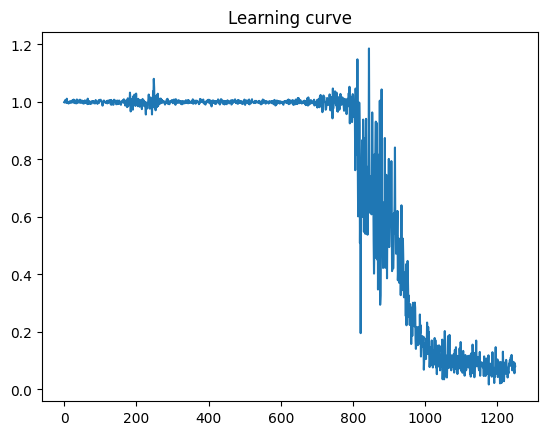

RECURRENT WEIGHT MATRIX:
None
Validation Loss: 0.1012, Accuracy: 1.0000


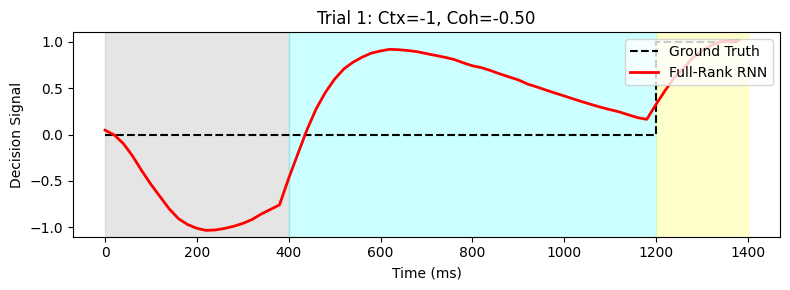

In [ ]:
# 4. Training a Full-Rank RNN on the XOR Task
%pip install torch numpy matplotlib
%load_ext autoreload
%autoreload 2

import sys
sys.path.append(r'C:\Users\13911\Desktop') 

import torch
import numpy as np
import matplotlib.pyplot as plt
from LowRank import LowRankRNN, loss_mse, train, accuracy_general
from low_rank_rnns.helpers import map_device
from math import floor


deltaT = 20.
t_ctx     = 400
t_stim    = 800
t_dec     = 200
t_ctx_steps  = floor(t_ctx/deltaT)
t_stim_steps = floor(t_stim/deltaT)
t_dec_steps  = floor(t_dec/deltaT)
t_total      = t_ctx_steps + t_stim_steps + t_dec_steps



INPUT_SIZE  = 3      # context + coherence
HIDDEN_SIZE = 512    
OUTPUT_SIZE = 1      
NOISE_STD   = 0.02   
ALPHA       = 0.1    # dt/tau

net = LowRankRNN(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    output_size=OUTPUT_SIZE,
    noise_std=NOISE_STD,
    alpha=ALPHA,
    rank=2,
    train_wi=False,
        train_wo=False,
        train_wrec=True,
        train_h0=False,
        train_si=True,
        train_so=True,
        wi_init=None,
        wo_init=None,
        m_init=None,
        n_init=None,
        si_init=None,
        so_init=None,
        h0_init=None,
)


X_all, Y_all, M_all, params_all = generate_xor_batch(n_trials=500, std=5e-2)
split = int(0.8 * X_all.shape[0])
X_tr, X_val = X_all[:split], X_all[split:]
Y_tr, Y_val = Y_all[:split], Y_all[split:]
M_tr, M_val = M_all[:split], M_all[split:]

X_tr, Y_tr, M_tr, X_val, Y_val, M_val = map_device(
    [X_tr, Y_tr, M_tr, X_val, Y_val, M_val], net
)


def run_training():
    train(
        net,
        X_tr, Y_tr, M_tr,
        n_epochs=50,
        lr=1e-2,#1e-3,
        batch_size=16,#128,
        plot_learning_curve=True,
        plot_gradient=False,
        clip_gradient=0.1,
        cuda=torch.cuda.is_available(),
        keep_best=True,
    )
    
    with torch.no_grad():
        out = net(X_val)
        val_loss = loss_mse(out, Y_val, M_val).item()
        val_acc  = accuracy_general(out, Y_val, M_val).item()
        print(f"Validation Loss: {val_loss:.4f}, Accuracy: {val_acc:.4f}")


if __name__ == '__main__':
    run_training()


net.eval()
trial_idx = 1
ctx, coh, _ = params_all[split + trial_idx]
x, y_true, _ = make_single_xor_trial(ctx, 0.5)
with torch.no_grad():
    y_pred = net(x)[0, :, 0].cpu().numpy()
    y_true = y_true[0, :, 0].numpy()
t = np.arange(t_total) * deltaT

plt.figure(figsize=(8,3))
plt.step(t, y_true, where='post', label='Ground Truth', ls='--', c='k')
plt.plot(t, y_pred, label='Full-Rank RNN', c='r', lw=2)
for name, s, e, color in [
    ('Ctx', 0, t_ctx_steps, 'gray'),
    ('Stim', t_ctx_steps, t_ctx_steps+t_stim_steps, 'cyan'),
    ('Dec', t_ctx_steps+t_stim_steps, t_total, 'yellow'),
]:
    plt.axvspan(s*deltaT, e*deltaT, color=color, alpha=0.2)
plt.xlabel('Time (ms)')
plt.ylabel('Decision Signal')
plt.ylim(-1.1, 1.1)
plt.legend(loc='upper right')
plt.title(f'Trial {trial_idx}: Ctx={ctx}, Coh={coh:.2f}')
plt.tight_layout()
plt.show()


In [ ]:


def plot_multiple_xor_pred(X, Y_true, Y_pred, params, trial_indices, deltaT,
                          t_ctx_steps, t_stim_steps, t_total):
    n = len(trial_indices)
    fig, axes = plt.subplots(n, 3, figsize=(12, n * 1.5), sharex=True)
    t = np.arange(t_total) * deltaT
    phases = [
        ('Context', 0, t_ctx_steps, 'gray'),
        ('Stimulus', t_ctx_steps, t_ctx_steps + t_stim_steps, 'cyan'),
        ('Decision', t_ctx_steps + t_stim_steps, t_total, 'yellow')
    ]
    for row, idx in enumerate(trial_indices):
        ctx, coh, _ = params[idx]
        ax_ctx, ax_coh, ax_act = axes[row]
        ax_ctx.plot(t, X[idx, :, 0].numpy(), color='tab:purple')
        ax_ctx.set_ylim(-1, 1)
        if row == 0: ax_ctx.set_title('Context')
        ax_coh.plot(t, X[idx, :, 1].numpy(), color='tab:green')
        ax_coh.set_ylim(-1, 1)
        if row == 0: ax_coh.set_title('Coherence')
        
        ax_act.step(t, Y_true[idx, :, 0].numpy(), where='post', color='k', linestyle='--', label='Ground Truth')
        ax_act.plot(t, Y_pred[idx], color='r', lw=2, label='Pred')
        ax_act.set_ylim(-1.1, 1.1)
        if row == 0: ax_act.set_title('Network Output')
        for ax in (ax_ctx, ax_coh, ax_act):
            for name, start, end, color in phases:
                ax.axvspan(start * deltaT, end * deltaT, color=color, alpha=0.2)
        axes[row, 0].set_ylabel(f'Trial {idx}')
        axes[row, 2].annotate(
            f'Ctx={ctx}, C={coh:.4f}',
            xy=(1.01, 0.5), xycoords='axes fraction',
            va='center', fontsize=8
        )
        if row == 0:
            ax_act.legend(loc='upper right', fontsize=8)
    axes[-1, 0].set_xlabel('Time (ms)')
    plt.tight_layout()
    plt.show()


n_sel = len(coherences) * 2
X_sel = torch.zeros(n_sel, t_total, 3)
Y_sel = torch.zeros(n_sel, t_total, 1)
params_sel = []
idx = 0
for coh in coherences:
    for ctx in [-1, 1]:
        x, y, _ = make_single_xor_trial(ctx, float(coh))
        X_sel[idx] = x
        Y_sel[idx] = y
        params_sel.append((ctx, float(coh), int(y[0, -1, 0])))
        idx += 1


net.eval()
with torch.no_grad():
    Y_pred = net(X_sel).cpu().numpy()[:, :, 0]


plot_multiple_xor_pred(X_sel, Y_sel, Y_pred, params_sel, list(range(n_sel)),
                       deltaT, t_ctx_steps, t_stim_steps, t_total)

coh -0.5
coh -0.25
coh -0.125
coh -0.0625
coh 0.0625
coh 0.125
coh 0.25
coh 0.5


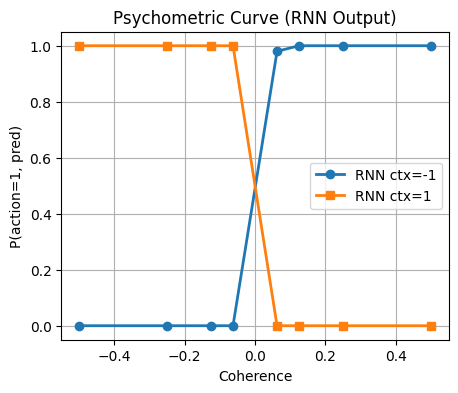

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

n_rep = 50  
cohs = np.sort(coherences)
probs_pred_ctx_neg1 = []
probs_pred_ctx1 = []

for coh in cohs:
    # ctx = -1
    outs0 = []
    for _ in range(n_rep):
        x, _, _ = make_single_xor_trial(-1, coh, std=0.05, coh_noise_mean=0.5,coh_noise_std=0.05)#常用占位写法，只用到x
        with torch.no_grad():
            y_pred = net(x).cpu().numpy()[0, -1, 0]  
        outs0.append(y_pred > 0.5)  
    probs_pred_ctx_neg1.append(np.mean(outs0))

    # ctx = 1
    outs1 = []
    print('coh',coh)
    for _ in range(n_rep):
        x, _, _ = make_single_xor_trial(1, coh, std=0.05, coh_noise_mean=0.5, coh_noise_std=0.05)
        with torch.no_grad():
            y_pred = net(x).cpu().numpy()[0, -1, 0]
        outs1.append(y_pred > 0.5)
    probs_pred_ctx1.append(np.mean(outs1))
    
cohs = np.sort(np.array(coherences))
plt.figure(figsize=(5,4))
plt.plot(cohs, probs_pred_ctx_neg1, 'o-', lw=2, label='RNN ctx=-1')
plt.plot(cohs, probs_pred_ctx1, 's-', lw=2, label='RNN ctx=1')
plt.xlabel('Coherence')
plt.ylabel('P(action=1, pred)')
plt.title('Psychometric Curve (RNN Output)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# notebook: load_and_simulate.ipynb

import torch
import numpy as np


import sys
sys.path.append("/Users/tinaguo/Desktop/XOR TASK CODE/Lowrank")

from LowRank import LowRankRNN   


INPUT_SIZE  = 3
HIDDEN_SIZE = 512
OUTPUT_SIZE = 1
NOISE_STD   = 0.02
ALPHA       = 0.1
net = LowRankRNN(
    input_size=INPUT_SIZE, hidden_size=HIDDEN_SIZE, output_size=OUTPUT_SIZE,
    noise_std=NOISE_STD, alpha=ALPHA, rank=2,
    train_wi=False, train_wo=False, train_wrec=True,
    train_h0=False, train_si=True, train_so=True,
)


state = torch.load("/Users/tinaguo/Desktop/XOR TASK CODE/Lowrank/LowRank.pth", map_location="cpu")
net.load_state_dict(state)
net.eval()

LowRankRNN()

In [174]:
import numpy as np
import torch

def compute_universal_m_and_inputs(net, preserve_m_norm=True, write_back=False, eps_tol=None, orthogonalize_mn=True):
    """
    Compute orthogonalized m and wi vectors. 
    If orthogonalize_mn=True, first performs SVD reparametrization on m and n matrices.
    """
    device = next(net.parameters()).device
    dtype = next(net.parameters()).dtype

    # Step 1: SVD reparametrization of m and n (similar to modules.py svd_reparametrization)
    if orthogonalize_mn:
        with torch.no_grad():
            # Get current m and n
            m_orig = net.m.detach().cpu().numpy().astype(float)  # (H, r)
            n_orig = net.n.detach().cpu().numpy().astype(float)  # (H, r)
            
            # Compute recurrent structure W_rec = m @ n^T
            structure = m_orig @ n_orig.T  # (H, H)
            
            # SVD decomposition
            U, s, Vt = np.linalg.svd(structure, full_matrices=False)
            
            # Keep only rank components
            H, r = m_orig.shape
            U = U[:, :r]
            s = s[:r] 
            Vt = Vt[:r, :]
            
            # Reparametrize: m = U * sqrt(s), n = V * sqrt(s) where V = Vt.T
            m_orth = U * np.sqrt(s[np.newaxis, :])  # (H, r)
            n_orth = Vt.T * np.sqrt(s[np.newaxis, :])  # (H, r)
            
            #Update network's m and n temporarily for our computation
            m_t = m_orth
            print(f"SVD reparametrization: singular values = {s}")
    else:
        m_t = net.m.detach().cpu().numpy().astype(float)   # (H, r)
    
    H, r = m_t.shape

    wi_tensor = net.wi.detach().cpu().numpy().astype(float)  # (input_size, H)
    input_size = wi_tensor.shape[0]
    if input_size > 0:
        W_cols = wi_tensor.T.copy()  # (H, input_size)
    else:
        W_cols = np.zeros((H, 0), dtype=float)

    # SVD for column-space basis
    U, svals, Vt = np.linalg.svd(m_t, full_matrices=False)
    if eps_tol is None:
        eps_tol = np.finfo(float).eps * max(m_t.shape) * (svals.max() if svals.size else 0.0)
    rank_eff = np.count_nonzero(svals > eps_tol)
    Qm = U[:, :rank_eff] if rank_eff > 0 else np.zeros((H, 0), dtype=float)

    # Build new_m by Modified Gram-Schmidt per-column (preserve per-column semantics)
    new_m = np.zeros_like(m_t)
    orig_norms = np.linalg.norm(m_t, axis=0)
    Q_cols = []
    for i in range(r):
        v = m_t[:, i].copy()
        for q in Q_cols:
            v -= q * (q.dot(v))
        for q in Q_cols:  # re-orth
            v -= q * (q.dot(v))
        norm_v = np.linalg.norm(v)
        if norm_v > eps_tol:
            q = v / norm_v
            Q_cols.append(q)
            if preserve_m_norm:
                scale = orig_norms[i] if orig_norms[i] > 0 else norm_v
                new_m[:, i] = q * scale
            else:
                new_m[:, i] = q
        else:
            new_m[:, i] = 0.0

    # Now project inputs once onto orthogonal complement of Qm:
    if Qm.size == 0 or W_cols.size == 0:
        new_W_cols = W_cols.copy()
    else:
        proj = Qm.dot(Qm.T.dot(W_cols))   # (H, input_size)
        new_W_cols = W_cols - proj

    # Orthogonalize new_W_cols among themselves (MGS) and preserve norms
    if input_size == 0:
        new_W_cols_orth = new_W_cols.copy()
    else:
        orig_w_norms = np.linalg.norm(W_cols, axis=0)
        new_W_cols_orth = np.zeros_like(new_W_cols)
        Qw_list = []
        for j in range(input_size):
            v = new_W_cols[:, j].copy()
            for q in Qw_list:
                v -= q * (q.dot(v))
            for q in Qw_list:
                v -= q * (q.dot(v))
            norm_v = np.linalg.norm(v)
            if norm_v > eps_tol:
                qj = v / norm_v
                Qw_list.append(qj)
                scale = orig_w_norms[j] if orig_w_norms[j] > 0 else norm_v
                new_W_cols_orth[:, j] = qj * scale
            else:
                new_W_cols_orth[:, j] = 0.0
        # small correction to re-project any Qm components
        if Qm.size != 0 and len(Qw_list) > 0:
            correction = Qm.dot(Qm.T.dot(new_W_cols_orth))
            new_W_cols_orth -= correction

    new_wi_rows = new_W_cols_orth.T  # (input_size, H)

    # convert to torch and attach
    m_univ = torch.from_numpy(new_m).to(device=device, dtype=dtype)
    wi_univ = torch.from_numpy(new_wi_rows).to(device=device, dtype=dtype)

    net.m_univ = m_univ
    net.wi_univ = wi_univ
    
    # If SVD reparametrization was performed, also store the orthogonalized n
    if orthogonalize_mn:
        n_univ = torch.from_numpy(n_orth).to(device=device, dtype=dtype)
        net.n_univ = n_univ

    if write_back:
        with torch.no_grad():
            net.m.data.copy_(m_univ)
            net.wi.data.copy_(wi_univ)
            if orthogonalize_mn:
                net.n.data.copy_(n_univ)

    return net.m_univ, net.wi_univ


In [175]:
import numpy as np

def simulate_lowrank_dynamics(m_univ, n, wi_univ, W_out, alpha, nonlin,
                              x_seq, hidden_size, h0=None, noise_std=0.0):
    """
    Robust simulate that auto-corrects common shape mistakes:
      - accepts m_univ as (H, r) or (r, H) and fixes
      - accepts n as (H, r) or (r, H) and fixes
      - accepts wi_univ as (H, input_dim) or (input_dim, H) or (Nin, H)
    Returns h_seq shape (T, H).
    """
    T, input_dim = x_seq.shape
    H = hidden_size
    # convert to numpy
    m = np.asarray(m_univ)
    n_mat = np.asarray(n)
    wi = np.asarray(wi_univ)

    # --- fix orientations automatically ---
    # m should be (H, r)
    if m.ndim != 2:
        raise ValueError("m_univ must be 2D")
    if m.shape[0] == H and m.shape[1] != H:
        pass
    elif m.shape[1] == H and m.shape[0] != H:
        # probably transposed: (r, H) -> transpose to (H, r)
        m = m.T
    else:
        # allow square HxH but then r = H
        pass
    # n should be (H, r)
    if n_mat.ndim != 2:
        raise ValueError("n must be 2D")
    if n_mat.shape == m.shape:
        # fine
        pass
    elif n_mat.shape[::-1] == m.shape:
        n_mat = n_mat.T
    else:
        # try to infer: if n is (r, H), transpose
        if n_mat.shape[0] == m.shape[1] and n_mat.shape[1] == m.shape[0]:
            n_mat = n_mat.T
        else:
            raise ValueError(f"Cannot reconcile shapes: m {m.shape}, n {n_mat.shape}")

    r = m.shape[1]  # effective r

    # wi -> we want wi_for_sim to be (H, input_dim)
    if wi.ndim != 2:
        raise ValueError("wi_univ must be 2D")
    if wi.shape == (H, input_dim):
        wi_for_sim = wi
    elif wi.shape == (input_dim, H):
        wi_for_sim = wi.T
    elif wi.shape == (input_dim, H) or (wi.shape[0] == input_dim and wi.shape[1] == H):
        wi_for_sim = wi.T
    elif wi.shape[1] == H and wi.shape[0] == input_dim:
        wi_for_sim = wi.T
    elif wi.shape[0] == H and wi.shape[1] != input_dim:
        # maybe wi is (H, Nin) but x_seq has input_dim; try to slice or raise
        if wi.shape[1] == x_seq.shape[1]:
            wi_for_sim = wi
        else:
            raise ValueError(f"Unsupported wi shape {wi.shape} for input_dim {input_dim}")
    else:
        # last resort: try transpose
        wi_for_sim = wi.T
        if wi_for_sim.shape != (H, input_dim):
            raise ValueError(f"wi_univ shape {wi.shape} incompatible with x_seq shape {(T,input_dim)}")

    # simulation
    h_seq = np.zeros((T, H), dtype=float)
    h = np.zeros(H) if h0 is None else h0.copy()

    for t in range(T):
        noise = np.random.randn(H) * noise_std
        r_vec = nonlin(h)                      # (H,)
        # compute low-rank term: m @ (n.T @ r_vec) / H  with shapes:
        # m: (H,r), n_mat: (H,r) => n_mat.T: (r,H); (r,H)@(H,) -> (r,)
        inner = n_mat.T.dot(r_vec)   # shape (r,)
        lowrank_term = m.dot(inner) / float(H)   # (H,)

        # input term: (H, input_dim) @ (input_dim,) -> (H,)
        input_term = wi_for_sim.dot(x_seq[t])

        h = h + noise + alpha * (-h + lowrank_term + input_term)
        h_seq[t] = h

    return h_seq


In [186]:
m_univ, wi_univ = compute_universal_m_and_inputs(net, preserve_m_norm=True, write_back=False)

SVD reparametrization: singular values = [3198.18710788  589.82417675]


In [ ]:

print(f"Has n_univ: {hasattr(net, 'n_univ')}")
if hasattr(net, 'n_univ'):
    print(f"n_univ shape: {net.n_univ.shape}")
else:
    print("n_univ not found, using original n matrix")
    print(f"Original n shape: {net.n.shape}")

Has n_univ: True
n_univ shape: torch.Size([512, 2])


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def compute_kappas_from_net(net, x, use_m_univ=True, use_wi_univ=True,
                            normalize_by_paper=True):
   
    net_device = next(net.parameters()).device
    x_dev = x.to(net_device)
    with torch.no_grad():
        out, trajectories = net(x_dev, return_dynamics=True)  # trajectories: (B, T+1, H)
    
    h = trajectories[:, 1:, :].cpu().numpy()   # shape (B, T, H)
    B, T, H = h.shape

    
    if use_m_univ and hasattr(net, "m_univ"):
        m_mat = net.m_univ.detach().cpu().numpy()  # (H, r)
    else:
        m_mat = net.m.detach().cpu().numpy()       # (H, r)
    r = m_mat.shape[1]

    
    if use_wi_univ and hasattr(net, "wi_univ"):
        wi_rows = net.wi_univ.detach().cpu().numpy()  # (Nin, H)
    else:
        wi_rows = net.wi.detach().cpu().numpy()       # (Nin, H)

    Nin = wi_rows.shape[0]

    
    dot_m = np.einsum('bth,hr->btr', h, m_mat)    # (B, T, r)
    dot_wi = np.einsum('bth,nh->btn', h, wi_rows) # (B, T, Nin)

    if normalize_by_paper:
       
        norms_m = np.linalg.norm(m_mat, axis=0)    # (r,)
        denom_m = (norms_m**2) * float(H)          # (r,)
        denom_m[denom_m == 0] = 1.0                

        # input var: vs = (1/||I_perp||^2) * (1/N) * sum_j I_perp_j xj(t)
        norms_w = np.linalg.norm(wi_rows, axis=1)  # (Nin,)
        denom_w = (norms_w**2) * float(H)
        denom_w[denom_w == 0] = 1.0

        kappas = dot_m / denom_m[np.newaxis, np.newaxis, :]      # (B, T, r)
        kappainput = dot_wi / denom_w[np.newaxis, np.newaxis, :] # (B, T, Nin)
    else:
       
        kappas = dot_m.copy()
        kappainput = dot_wi.copy()

    return kappas, kappainput, h

def plot_kappas_time(kappas, kappainput, deltaT, t_ctx_steps, t_stim_steps, trial_idx=0,
                     labels_m=None, labels_input=None):
    
    B, T, r = kappas.shape
    Nin = kappainput.shape[2]
    t = np.arange(T) * deltaT

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    
    ax_kappa = axes[0]
    for i in range(r):
        label = labels_m[i] if labels_m else f'κ{i+1}'
        ax_kappa.plot(t, kappas[trial_idx, :, i], label=label, linewidth=2)
    ax_kappa.set_ylabel('Internal κr')
    ax_kappa.legend()
    ax_kappa.grid(True, alpha=0.3)

    
    ax_input = axes[1]
    for i in range(Nin):
        label = labels_input[i] if labels_input else f'v{i+1}'
        ax_input.plot(t, kappainput[trial_idx, :, i], label=label, linewidth=2)
    ax_input.set_ylabel('External vs')
    ax_input.set_xlabel('Time (ms)')
    ax_input.legend()
    ax_input.grid(True, alpha=0.3)

    
    for ax in axes:
        ax.axvspan(0, t_ctx_steps * deltaT, color='gray', alpha=0.2, label='Context')
        ax.axvspan(t_ctx_steps * deltaT, (t_ctx_steps + t_stim_steps) * deltaT, 
                  color='cyan', alpha=0.2, label='Stimulus')
        ax.axvspan((t_ctx_steps + t_stim_steps) * deltaT, T * deltaT, 
                  color='yellow', alpha=0.2, label='Decision')

    plt.tight_layout()
    plt.show()


ctx = 1
coh = 0.5
x, y_true, mask_single = make_single_xor_trial(ctx, coh)  
kappas, kappainput, h = compute_kappas_from_net(net, x, normalize_by_paper=True)

print("Successfully computed kappas!")
print(f"kappas shape: {kappas.shape}")
print(f"kappainput shape: {kappainput.shape}")
print(f"h shape: {h.shape}")

Successfully computed kappas!
kappas shape: (1, 75, 2)
kappainput shape: (1, 75, 3)
h shape: (1, 75, 512)


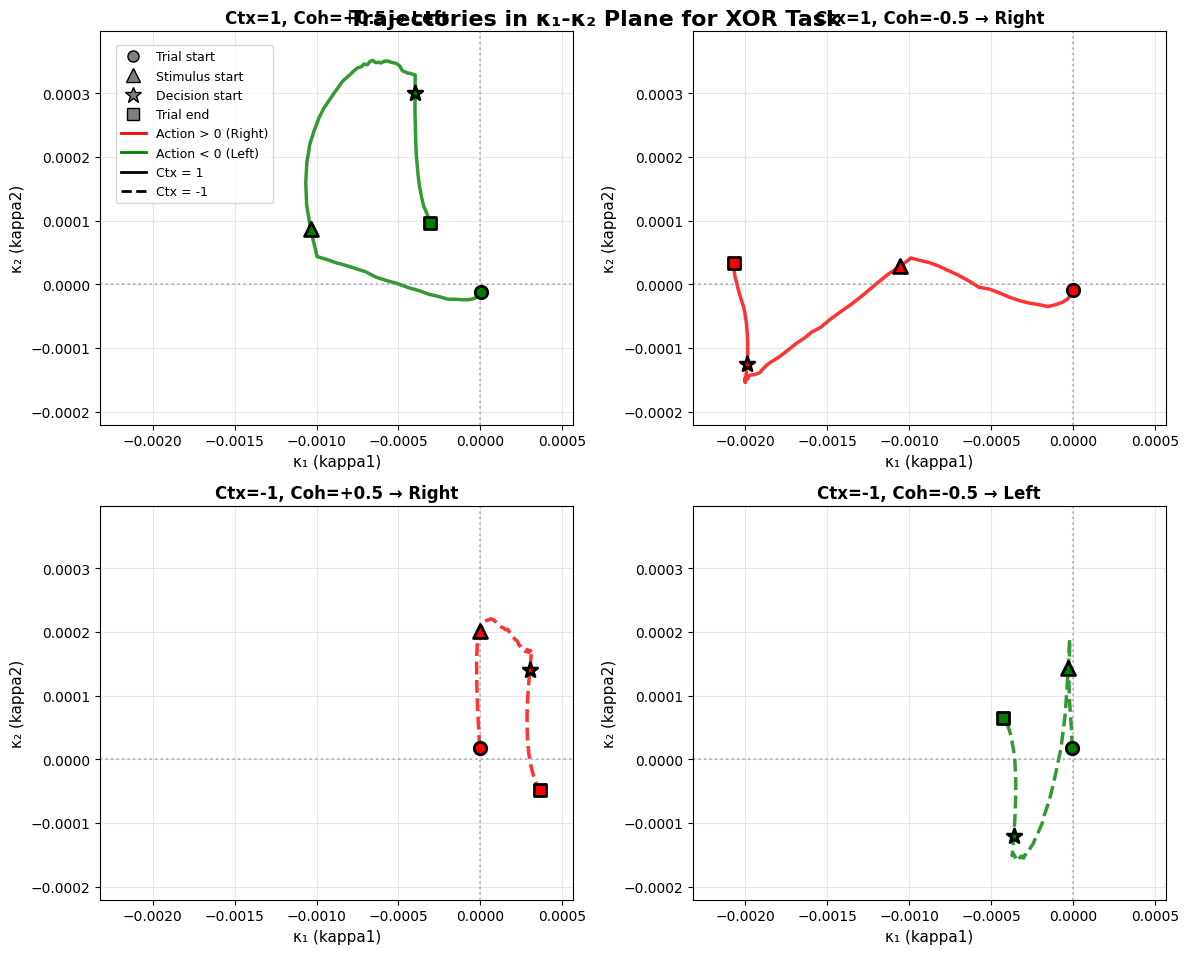

In [ ]:
def plot_kappa_trajectories_2d(net, trial_configs, deltaT, t_ctx_steps, t_stim_steps, 
                               figsize=(12, 10), normalize_by_paper=True):
    
    
    
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    axes = axes.flatten()
    
    
    configs = [(1, 0.5), (1, -0.5), (-1, 0.5), (-1, -0.5)]
    
    for idx, (ctx, coh) in enumerate(configs):
        ax = axes[idx]
        
        
        x, y_true, mask_single = make_single_xor_trial(ctx, coh)
        
        kappas, kappainput, h = compute_kappas_from_net(
            net, x.unsqueeze(0) if x.ndim==2 else x, 
            normalize_by_paper=normalize_by_paper
        )
        kappa1 = kappas[0, :, 0]  
        kappa2 = kappas[0, :, 1]  
        
       
        decision_start = t_ctx_steps + t_stim_steps
        final_action = np.mean(y_true[0, decision_start:, 0].numpy())
        
        color = 'red' if final_action > 0 else 'green'
        linestyle = '-' if ctx == 1 else '--'
        ax.plot(kappa1, kappa2, color=color, linestyle=linestyle, linewidth=2.5, alpha=0.8)
        ax.scatter(kappa1[0], kappa2[0], marker='o', s=80, color=color, 
                  edgecolor='black', linewidth=2, zorder=5, label='Trial start')
        
        if t_ctx_steps < len(kappa1):
            ax.scatter(kappa1[t_ctx_steps], kappa2[t_ctx_steps], marker='^', s=100, 
                      color=color, edgecolor='black', linewidth=2, zorder=5, label='Stimulus start')

        decision_idx = t_ctx_steps + t_stim_steps
        if decision_idx < len(kappa1):
            ax.scatter(kappa1[decision_idx], kappa2[decision_idx], marker='*', s=120, 
                      color=color, edgecolor='black', linewidth=2, zorder=5, label='Decision start')
        
        ax.scatter(kappa1[-1], kappa2[-1], marker='s', s=80, color=color, 
                  edgecolor='black', linewidth=2, zorder=5, label='Trial end')
        
        ax.axhline(y=0, color='gray', linestyle=':', alpha=0.5)
        ax.axvline(x=0, color='gray', linestyle=':', alpha=0.5)
        
        action_str = "Right" if final_action > 0 else "Left"
        ctx_str = "Ctx=1" if ctx == 1 else "Ctx=-1"
        ax.set_title(f'{ctx_str}, Coh={coh:+.1f} → {action_str}', fontsize=12, fontweight='bold')
        ax.set_xlabel('κ₁ (kappa1)', fontsize=11)
        ax.set_ylabel('κ₂ (kappa2)', fontsize=11)
       
        ax.grid(True, alpha=0.3)
        
        if idx == 0:

            from matplotlib.lines import Line2D
            legend_elements = [
                Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
                       markersize=8, label='Trial start', markeredgecolor='black'),
                Line2D([0], [0], marker='^', color='w', markerfacecolor='gray', 
                       markersize=10, label='Stimulus start', markeredgecolor='black'),
                Line2D([0], [0], marker='*', color='w', markerfacecolor='gray', 
                       markersize=12, label='Decision start', markeredgecolor='black'),
                Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', 
                       markersize=8, label='Trial end', markeredgecolor='black'),
                Line2D([0], [0], color='red', linewidth=2, label='Action > 0 (Right)'),
                Line2D([0], [0], color='green', linewidth=2, label='Action < 0 (Left)'),
                Line2D([0], [0], color='black', linestyle='-', linewidth=2, label='Ctx = 1'),
                Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='Ctx = -1')
            ]
            ax.legend(handles=legend_elements, loc='upper left', fontsize=9, 
                     bbox_to_anchor=(0.02, 0.98))
    
    all_kappa1 = []
    all_kappa2 = []
    
    for ctx, coh in configs:
        x, y_true, _ = make_single_xor_trial(ctx, coh)
        kappas, _, _ = compute_kappas_from_net(net, x.unsqueeze(0) if x.ndim==2 else x, 
                                              normalize_by_paper=normalize_by_paper)
        all_kappa1.extend(kappas[0, :, 0])
        all_kappa2.extend(kappas[0, :, 1])
    
    k1_min, k1_max = np.min(all_kappa1), np.max(all_kappa1)
    k2_min, k2_max = np.min(all_kappa2), np.max(all_kappa2)
    
    k1_margin = (k1_max - k1_min) * 0.1
    k2_margin = (k2_max - k2_min) * 0.1
    
    for ax in axes:
        ax.set_xlim(k1_min - k1_margin, k1_max + k1_margin)
        ax.set_ylim(k2_min - k2_margin, k2_max + k2_margin)
    
    plt.suptitle('Trajectories in κ₁-κ₂ Plane for XOR Task', fontsize=16, fontweight='bold', y=0.95)
    plt.tight_layout()
    plt.show()

plot_kappa_trajectories_2d(net, [], deltaT, t_ctx_steps, t_stim_steps)

Kappa ranges: κ₁ ∈ [-0.003, 0.001], κ₂ ∈ [-0.000, 0.000]
Computing decision boundary heatmap...
  Processing context -1...
  Processing context 1...


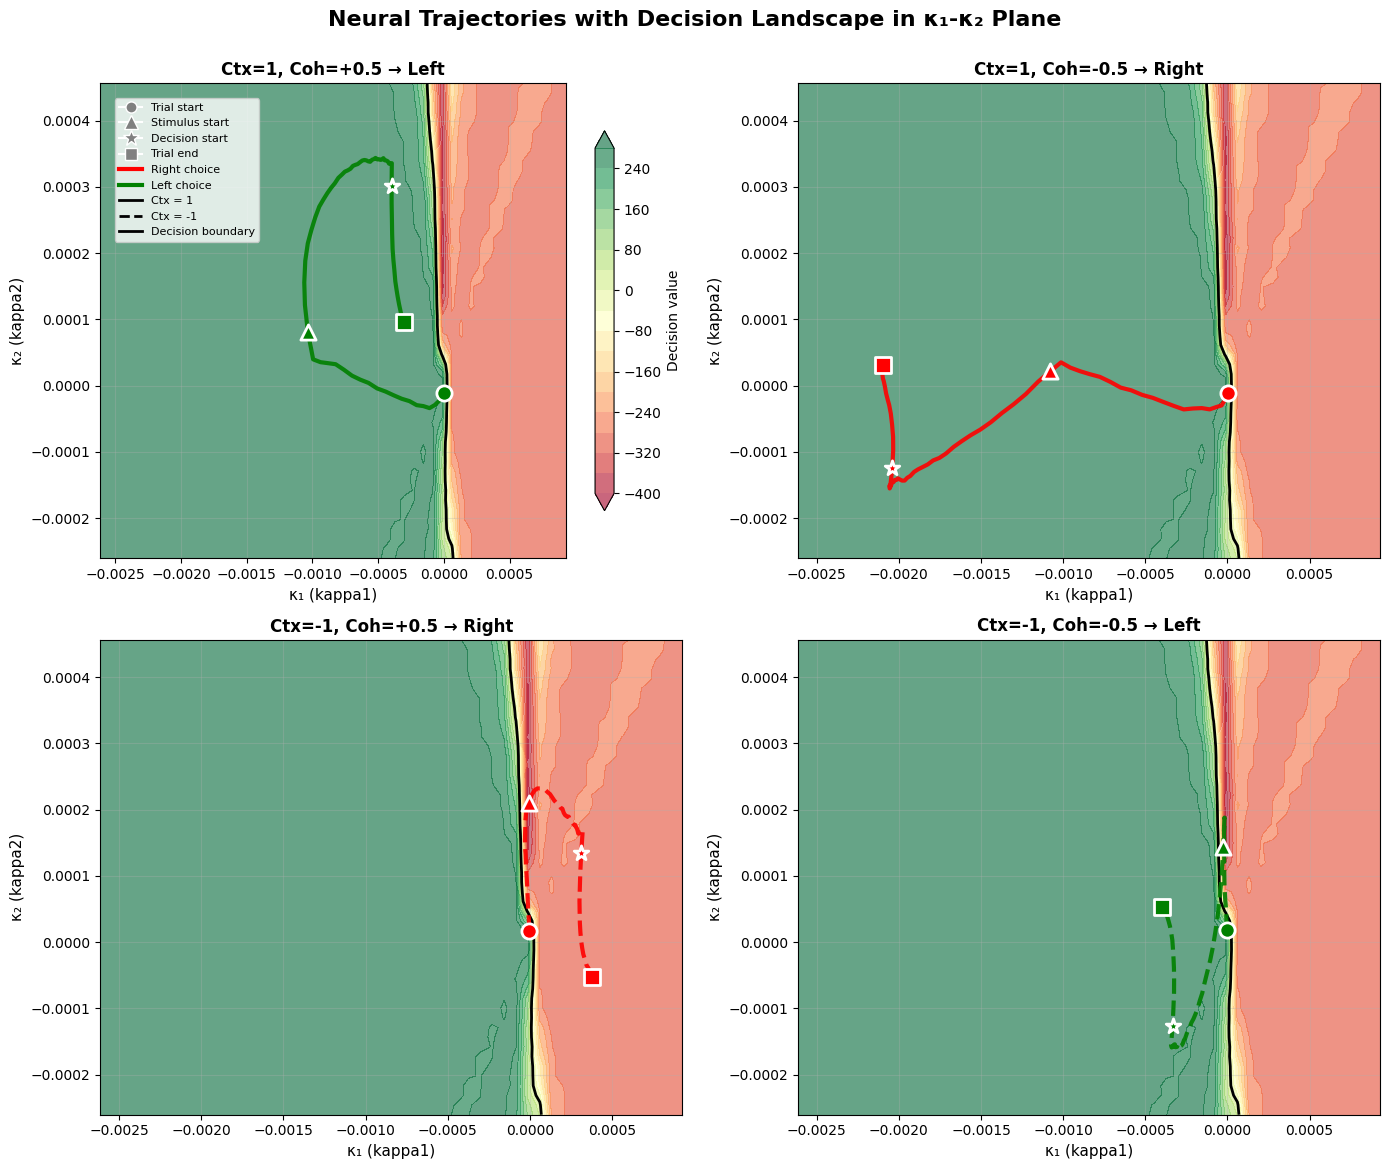


背景热力图说明:
- 红色区域: 网络倾向于输出 Right (action > 0)
- 绿色区域: 网络倾向于输出 Left (action < 0)
- 黑色实线: 决策边界 (action = 0)
- 轨迹颜色: 红色=Right choice, 蓝色=Left choice
- 轨迹线型: 实线=Ctx=1, 虚线=Ctx=-1


In [ ]:
def plot_kappa_trajectories_with_heatmap(net, deltaT, t_ctx_steps, t_stim_steps, 
                                        figsize=(14, 12), normalize_by_paper=True,
                                        grid_resolution=50, coh_test=0.25):
    
    
    configs = [(1, 0.5), (1, -0.5), (-1, 0.5), (-1, -0.5)]
    all_kappa1, all_kappa2 = [], []
    
    for ctx, coh in configs:
        x, _, _ = make_single_xor_trial(ctx, coh)
        kappas, _, _ = compute_kappas_from_net(net, x.unsqueeze(0) if x.ndim==2 else x, 
                                              normalize_by_paper=normalize_by_paper)
        all_kappa1.extend(kappas[0, :, 0])
        all_kappa2.extend(kappas[0, :, 1])
    
    k1_min, k1_max = np.min(all_kappa1), np.max(all_kappa1)
    k2_min, k2_max = np.min(all_kappa2), np.max(all_kappa2)
    k1_margin = (k1_max - k1_min) * 0.2
    k2_margin = (k2_max - k2_min) * 0.2
    k1_range = [k1_min - k1_margin, k1_max + k1_margin]
    k2_range = [k2_min - k2_margin, k2_max + k2_margin]
    
    print(f"Kappa ranges: κ₁ ∈ [{k1_range[0]:.3f}, {k1_range[1]:.3f}], κ₂ ∈ [{k2_range[0]:.3f}, {k2_range[1]:.3f}]")
    
    k1_grid = np.linspace(k1_range[0], k1_range[1], grid_resolution)
    k2_grid = np.linspace(k2_range[0], k2_range[1], grid_resolution)
    K1, K2 = np.meshgrid(k1_grid, k2_grid)
    
    device = next(net.parameters()).device
    if hasattr(net, 'm_univ'):
        m_mat = net.m_univ.detach().cpu().numpy()  # (H, r)
    else:
        m_mat = net.m.detach().cpu().numpy()
    
    if hasattr(net, 'wi_univ'):
        wi_rows = net.wi_univ.detach().cpu().numpy()  # (Nin, H)
    else:
        wi_rows = net.wi.detach().cpu().numpy()
    
    H = m_mat.shape[0]
    
    if normalize_by_paper:
        norms_m = np.linalg.norm(m_mat, axis=0)    # (r,)
        denom_m = (norms_m**2) * float(H)          # (r,)
        denom_m[denom_m == 0] = 1.0
    else:
        denom_m = np.ones(2)
    
    print("Computing decision boundary heatmap...")
    
    decision_maps = {}
    
    for ctx_idx, ctx in enumerate([-1, 1]):
        print(f"  Processing context {ctx}...")
        decision_values = np.zeros_like(K1)
        
        for i in range(grid_resolution):
            for j in range(grid_resolution):
                k1_val = K1[i, j]
                k2_val = K2[i, j]
                
                if normalize_by_paper:
                    proj1 = k1_val * denom_m[0]
                    proj2 = k2_val * denom_m[1]
                else:
                    proj1 = k1_val
                    proj2 = k2_val
                h_virtual = proj1 * m_mat[:, 0] + proj2 * m_mat[:, 1]
                
                with torch.no_grad():
                    h_tensor = torch.tensor(h_virtual, dtype=torch.float32).unsqueeze(0).to(device)
                    
                    x_virtual = torch.zeros(1, 1, 3).to(device)  # (batch=1, time=1, input_dim=3)
                    if ctx == -1:
                        x_virtual[0, 0, 0] = 1  # context channel 0
                    else:
                        x_virtual[0, 0, 1] = 1  # context channel 1  
                    x_virtual[0, 0, 2] = coh_test  # coherence channel
                    
                    r_t = torch.tanh(h_tensor)  # (1, H)
                    
                    if hasattr(net, 'wo'):
                        output = torch.matmul(r_t, net.wo)  # (1, output_size)
                    else:
                        output = torch.sum(r_t * 0.01, dim=1, keepdim=True)  # 简化版本
                    decision_values[i, j] = output[0, 0].cpu().item()
        
        decision_maps[ctx] = decision_values
    
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    axes = axes.flatten()
    
    for idx, (ctx, coh) in enumerate(configs):
        ax = axes[idx]
        heatmap_data = decision_maps[ctx]
        im = ax.contourf(K1, K2, heatmap_data, levels=20, cmap='RdYlGn', alpha=0.6, extend='both')
        
        ax.contour(K1, K2, heatmap_data, levels=[0], colors='black', linewidths=2, linestyles='-')
        
        x, y_true, _ = make_single_xor_trial(ctx, coh)
        kappas, _, _ = compute_kappas_from_net(
            net, x.unsqueeze(0) if x.ndim==2 else x, 
            normalize_by_paper=normalize_by_paper
        )
        
        kappa1 = kappas[0, :, 0]
        kappa2 = kappas[0, :, 1]
        
        decision_start = t_ctx_steps + t_stim_steps
        final_action = np.mean(y_true[0, decision_start:, 0].numpy())
        
        color = 'red' if final_action > 0 else 'green'
        linestyle = '-' if ctx == 1 else '--'
        ax.plot(kappa1, kappa2, color=color, linestyle=linestyle, linewidth=3, alpha=0.9, zorder=10)
        
        markers_config = [
            (0, 'o', 'Trial start'),
            (t_ctx_steps, '^', 'Stimulus start'),
            (t_ctx_steps + t_stim_steps, '*', 'Decision start'),
            (-1, 's', 'Trial end')
        ]
        
        for time_idx, marker, label in markers_config:
            if time_idx == -1:
                time_idx = len(kappa1) - 1
            if 0 <= time_idx < len(kappa1):
                ax.scatter(kappa1[time_idx], kappa2[time_idx], marker=marker, s=120, 
                          color=color, edgecolor='white', linewidth=2, zorder=15)
        
        action_str = "Right" if final_action > 0 else "Left"
        ctx_str = "Ctx=1" if ctx == 1 else "Ctx=-1"
        ax.set_title(f'{ctx_str}, Coh={coh:+.1f} → {action_str}', fontsize=12, fontweight='bold')
        ax.set_xlabel('κ₁ (kappa1)', fontsize=11)
        ax.set_ylabel('κ₂ (kappa2)', fontsize=11)
        ax.set_xlim(k1_range)
        ax.set_ylim(k2_range)
        ax.grid(True, alpha=0.3)
        
        if idx == 0:
            cbar = plt.colorbar(im, ax=ax, shrink=0.8)
            cbar.set_label('Decision value', fontsize=10)
            
            from matplotlib.lines import Line2D
            legend_elements = [
                Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
                       markersize=8, label='Trial start', markeredgecolor='white'),
                Line2D([0], [0], marker='^', color='w', markerfacecolor='gray', 
                       markersize=10, label='Stimulus start', markeredgecolor='white'),
                Line2D([0], [0], marker='*', color='w', markerfacecolor='gray', 
                       markersize=12, label='Decision start', markeredgecolor='white'),
                Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', 
                       markersize=8, label='Trial end', markeredgecolor='white'),
                Line2D([0], [0], color='red', linewidth=3, label='Right choice'),
                Line2D([0], [0], color='green', linewidth=3, label='Left choice'),
                Line2D([0], [0], color='black', linestyle='-', linewidth=2, label='Ctx = 1'),
                Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='Ctx = -1'),
                Line2D([0], [0], color='black', linewidth=2, label='Decision boundary')
            ]
            ax.legend(handles=legend_elements, loc='upper left', fontsize=8, 
                     bbox_to_anchor=(0.02, 0.98))
    
    plt.tight_layout(rect=[0, 0, 1, 0.94])  
    plt.suptitle('Neural Trajectories with Decision Landscape in κ₁-κ₂ Plane', 
                 fontsize=16, fontweight='bold', y=0.97)
    plt.show()
    
    
plot_kappa_trajectories_with_heatmap(net, deltaT, t_ctx_steps, t_stim_steps)

 生成多试验时间序列图...
Processing condition 1/4: Ctx=-1, Coh=+0.5 → Right
Processing condition 2/4: Ctx=-1, Coh=-0.5 → Left
Processing condition 3/4: Ctx=1, Coh=+0.5 → Left
Processing condition 4/4: Ctx=1, Coh=-0.5 → Right
统一y轴刻度设置:
  刻度间隔: 0.01
  刻度范围: [-0.010, 0.010]
  刻度数量: 3
  适用于: κ₁, κ₂, Input κ 所有子图


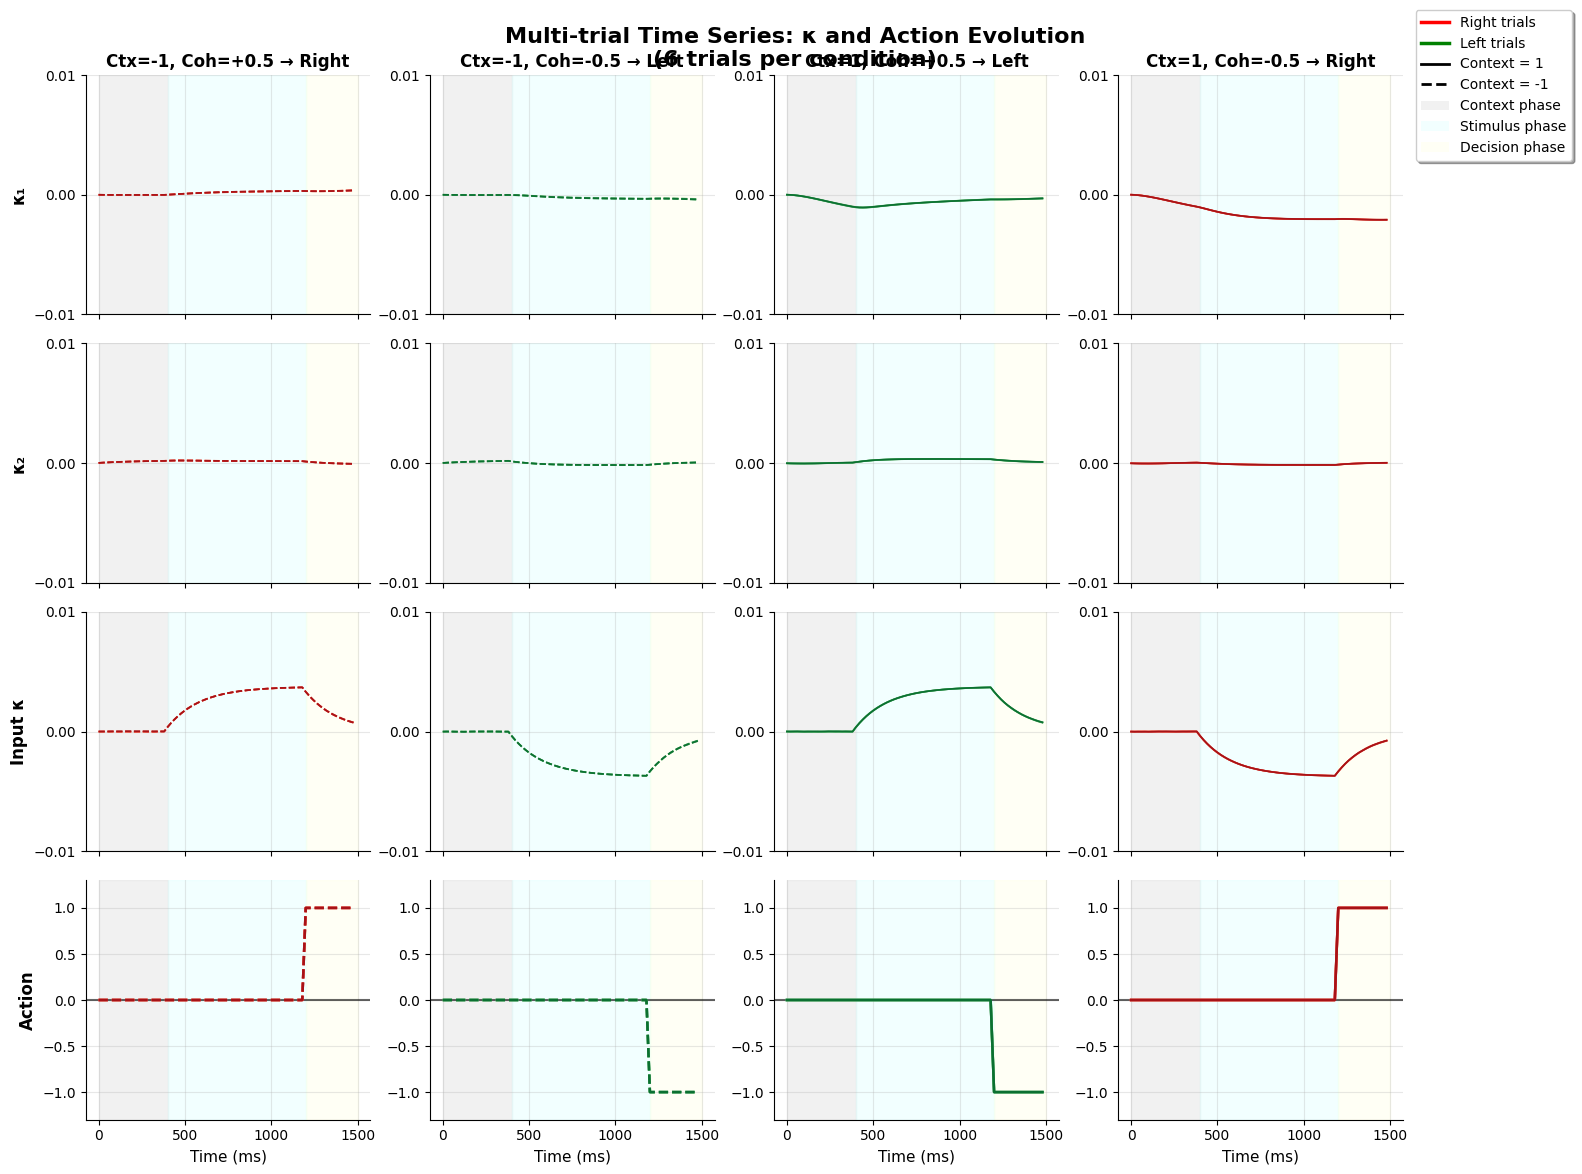


 图像说明:
• 行: 不同变量 (κ₁, κ₂, Input κ, Action)
• 列: 不同试验条件 (Context × Coherence)
• 线型: 实线=Context=1, 虚线=Context=-1
• 颜色: 红色=Right trials, 绿色=Left trials
• 背景: 灰=Context期, 青=Stimulus期, 黄=Decision期
• 每个面板显示6条轨迹的试验间变异


In [ ]:
def plot_kappa_time_series_multi_trials(net, n_trials_per_condition=8, deltaT=20, 
                                        t_ctx_steps=20, t_stim_steps=40, figsize=(16, 12),
                                        normalize_by_paper=True, add_noise=True, noise_std=0.005):
    
    conditions = [
        (-1, 0.5, "Right"),   # Context=-1, Coh=+0.5 → Right
        (-1, -0.5, "Left"),   # Context=-1, Coh=-0.5 → Left  
        (1, 0.5, "Left"),     # Context=1, Coh=+0.5 → Left
        (1, -0.5, "Right")    # Context=1, Coh=-0.5 → Right
    ]
    
    fig, axes = plt.subplots(4, 4, figsize=figsize, sharex=True)
    var_names = ['κ₁', 'κ₂', 'Input κ', 'Action']
    t_total = t_ctx_steps + t_stim_steps + 15  
    time_ms = np.arange(t_total) * deltaT
    
    phases = [
        ('Context', 0, t_ctx_steps, 'lightgray', 0.3),
        ('Stimulus', t_ctx_steps, t_ctx_steps + t_stim_steps, 'lightcyan', 0.4),
        ('Decision', t_ctx_steps + t_stim_steps, t_total, 'lightyellow', 0.3)
    ]
    
    all_kappa1_data = []
    all_kappa2_data = []
    all_input_kappa_data = []
    
    for cond_idx, (ctx, coh, expected_action) in enumerate(conditions):
        print(f"Processing condition {cond_idx+1}/4: Ctx={ctx}, Coh={coh:+.1f} → {expected_action}")
        
        condition_data = {
            'kappa1': [],
            'kappa2': [], 
            'input_kappa': [],
            'actions': []
        }
        
        for trial_i in range(n_trials_per_condition):
            
            noise_level = 0.01 if add_noise else 0.0
            x, y_true, _ = make_single_xor_trial(ctx, coh, std=noise_level)
            
            kappas, kappainput, _ = compute_kappas_from_net(
                net, x.unsqueeze(0) if x.ndim==2 else x, 
                normalize_by_paper=normalize_by_paper
            )
            
            max_len = min(t_total, kappas.shape[1])
            k1_traj = kappas[0, :max_len, 0]
            k2_traj = kappas[0, :max_len, 1]
            
            if kappainput.shape[2] > 2:
                input_traj = kappainput[0, :max_len, 2]
            else:
                input_traj = np.zeros(max_len)

            action_traj = y_true[0, :max_len, 0].numpy()
            
            if add_noise:
                k1_traj += np.random.normal(0, noise_std, k1_traj.shape)
                k2_traj += np.random.normal(0, noise_std, k2_traj.shape)
                input_traj += np.random.normal(0, noise_std*0.5, input_traj.shape)
            
            condition_data['kappa1'].append(k1_traj)
            condition_data['kappa2'].append(k2_traj)
            condition_data['input_kappa'].append(input_traj)
            condition_data['actions'].append(action_traj)
            
            all_kappa1_data.extend(k1_traj)
            all_kappa2_data.extend(k2_traj)
            all_input_kappa_data.extend(input_traj)
            
            all_kappa1_data.extend(k1_traj)
            all_kappa2_data.extend(k2_traj)
            all_input_kappa_data.extend(input_traj)
            
            all_kappa1_data.extend(k1_traj)
            all_kappa2_data.extend(k2_traj)
            all_input_kappa_data.extend(input_traj)
        
        linestyle = '-' if ctx == 1 else '--'  
        
        if expected_action == "Right":
            colors = plt.cm.Reds(np.linspace(0.3, 0.9, n_trials_per_condition))
        else:
            colors = plt.cm.Greens(np.linspace(0.3, 0.9, n_trials_per_condition))
        
        var_data = [
            condition_data['kappa1'],
            condition_data['kappa2'],
            condition_data['input_kappa'], 
            condition_data['actions']
        ]
        
        for var_idx, (var_trajs, var_name) in enumerate(zip(var_data, var_names)):
            ax = axes[var_idx, cond_idx]
            
            for phase_name, start, end, bg_color, alpha in phases:
                ax.axvspan(start * deltaT, end * deltaT, color=bg_color, alpha=alpha, zorder=0)
            
            for trial_idx, traj in enumerate(var_trajs):
                time_traj = time_ms[:len(traj)]
                
                ax.plot(time_traj, traj,
                       color=colors[trial_idx],
                       linestyle=linestyle,
                       linewidth=1.8 if var_name == 'Action' else 1.2,
                       alpha=0.7,
                       zorder=5)
            
            if var_name == 'Action':
                ax.axhline(y=0, color='black', linestyle='-', linewidth=1.5, alpha=0.6, zorder=3)
                ax.set_ylim(-1.3, 1.3)
            
            if var_idx == 0:
                ctx_str = "Ctx=1" if ctx == 1 else "Ctx=-1"
                ax.set_title(f'{ctx_str}, Coh={coh:+.1f} → {expected_action}', 
                           fontsize=12, fontweight='bold')
            
            if cond_idx == 0:
                ax.set_ylabel(var_name, fontsize=12, fontweight='bold')
            
            ax.grid(True, alpha=0.3, zorder=1)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            
            if var_idx == 3:
                ax.set_xlabel('Time (ms)', fontsize=11)
    
    if all_kappa1_data and all_kappa2_data and all_input_kappa_data:
        
        all_kappa_data = all_kappa1_data + all_kappa2_data + all_input_kappa_data
        global_min = np.min(all_kappa_data)
        global_max = np.max(all_kappa_data)
        
        tick_interval = 0.01  
        
        tick_min = np.floor(global_min / tick_interval) * tick_interval
        tick_max = np.ceil(global_max / tick_interval) * tick_interval
        
        yticks = np.arange(tick_min, tick_max + tick_interval, tick_interval)
        
        for cond_idx in range(4):  
            # κ₁
            axes[0, cond_idx].set_yticks(yticks)
            axes[0, cond_idx].set_ylim(tick_min, tick_max)
            
            # κ₂
            axes[1, cond_idx].set_yticks(yticks)
            axes[1, cond_idx].set_ylim(tick_min, tick_max)
            
            # Input κ
            axes[2, cond_idx].set_yticks(yticks)
            axes[2, cond_idx].set_ylim(tick_min, tick_max)
            
        
        print(f"统一y轴刻度设置:")
        print(f"  刻度间隔: {tick_interval}")
        print(f"  刻度范围: [{tick_min:.3f}, {tick_max:.3f}]")
        print(f"  刻度数量: {len(yticks)}")
        print(f"  适用于: κ₁, κ₂, Input κ 所有子图")
    
  
    legend_elements = [
        plt.Line2D([0], [0], color='red', linewidth=2.5, label='Right trials'),
        plt.Line2D([0], [0], color='green', linewidth=2.5, label='Left trials'),
        plt.Line2D([0], [0], color='black', linestyle='-', linewidth=2, label='Context = 1'),
        plt.Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='Context = -1'),
        plt.Rectangle((0,0),1,1, facecolor='lightgray', alpha=0.3, label='Context phase'),
        plt.Rectangle((0,0),1,1, facecolor='lightcyan', alpha=0.4, label='Stimulus phase'),
        plt.Rectangle((0,0),1,1, facecolor='lightyellow', alpha=0.3, label='Decision phase')
    ]
    
    fig.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(0.99, 0.98), 
               fontsize=10, frameon=True, fancybox=True, shadow=True)
    
    plt.suptitle(f'Multi-trial Time Series: κ and Action Evolution\n({n_trials_per_condition} trials per condition)', 
                 fontsize=16, fontweight='bold', y=0.96)
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.92, right=0.88)
    plt.show()
    
    print(f"\n 图像说明:")
    print(f"• 行: 不同变量 (κ₁, κ₂, Input κ, Action)")
    print(f"• 列: 不同试验条件 (Context × Coherence)")  
    print(f"• 线型: 实线=Context=1, 虚线=Context=-1")
    print(f"• 颜色: 红色=Right trials, 绿色=Left trials")
    print(f"• 背景: 灰=Context期, 青=Stimulus期, 黄=Decision期")
    print(f"• 每个面板显示{n_trials_per_condition}条轨迹的试验间变异")

print(" 生成多试验时间序列图...")
plot_kappa_time_series_multi_trials(net, n_trials_per_condition=6, add_noise=True, noise_std=0.00)

 生成多试验时间序列图...
Processing condition 1/4: Ctx=-1, Coh=+0.5 → Right
Processing condition 2/4: Ctx=-1, Coh=-0.5 → Left
Processing condition 3/4: Ctx=1, Coh=+0.5 → Left
Processing condition 4/4: Ctx=1, Coh=-0.5 → Right


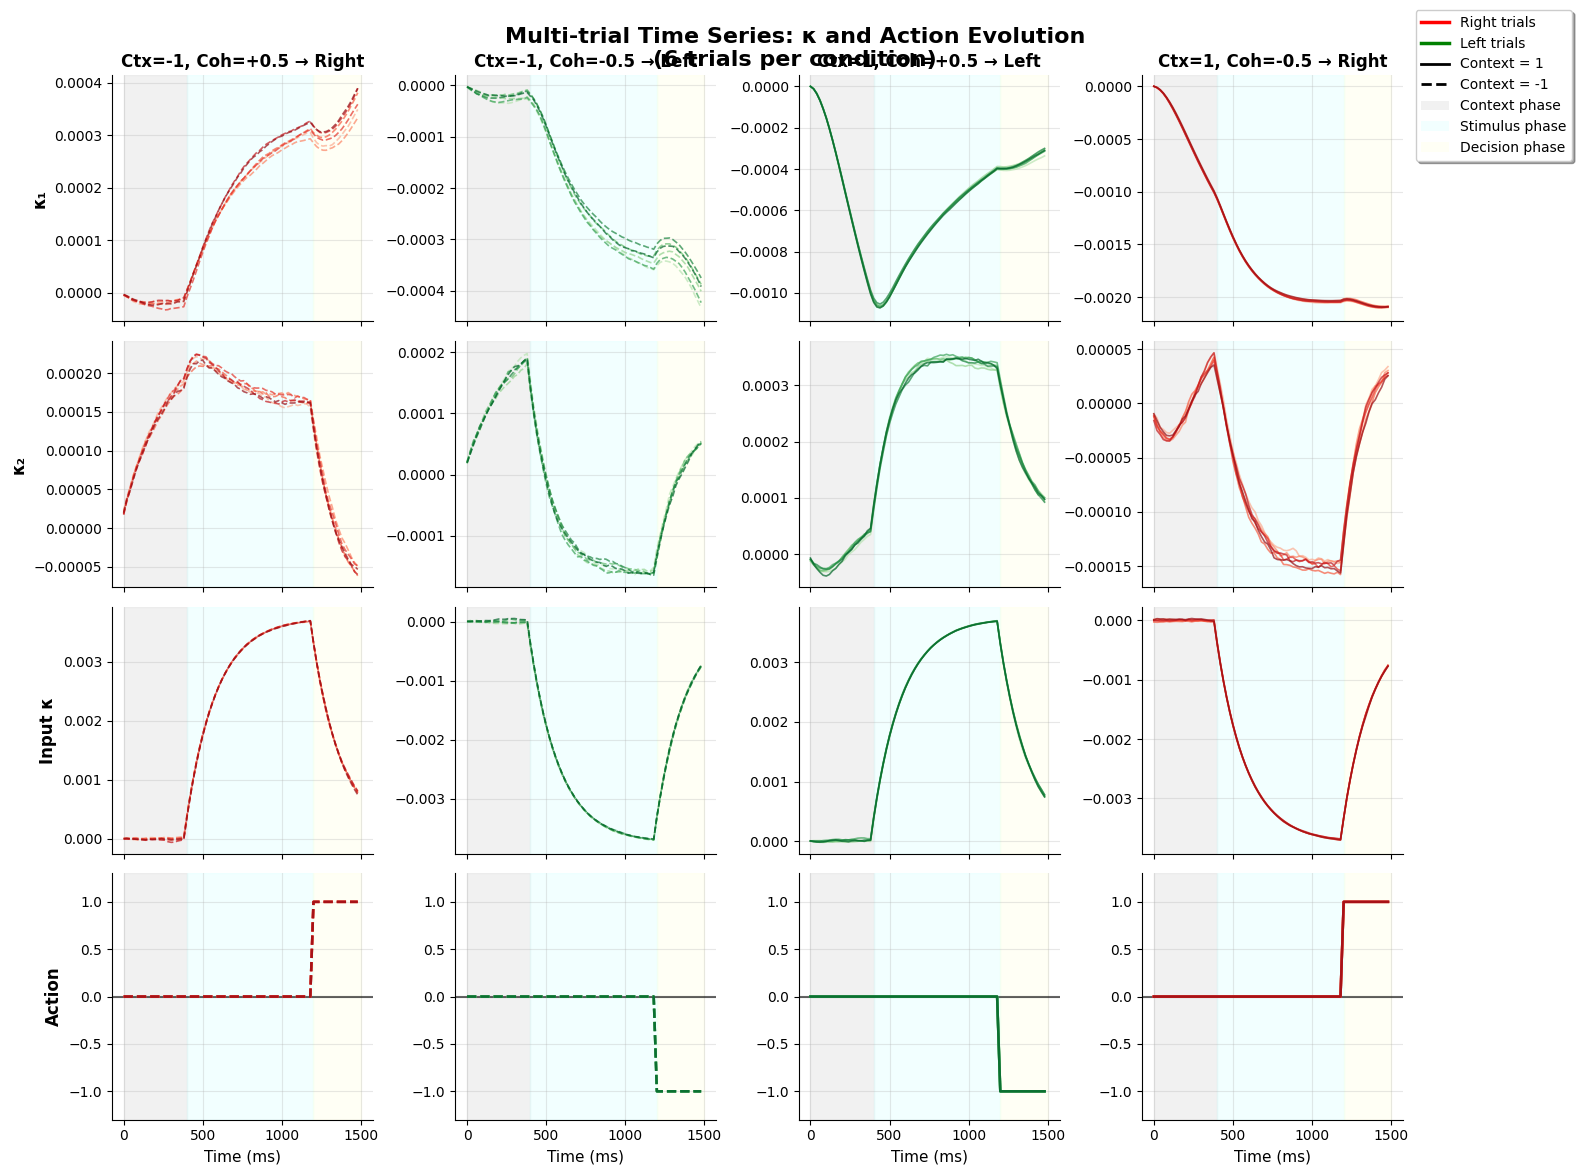


图像说明:
• 行: κ₁, κ₂, Input κ, Action
• 列: 不同试验条件 (Context × Coherence)
• 线型: 实线=Context=1, 虚线=Context=-1
• 颜色: 红=Right trials, 绿=Left trials
• 背景: 灰=Context期, 青=Stimulus期, 黄=Decision期
• 每个面板显示 6 条轨迹的试验间变异


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_kappa_time_series_multi_trials(
    net,
    n_trials_per_condition=8,
    deltaT=20,
    t_ctx_steps=20,
    t_stim_steps=40,
    figsize=(16, 12),
    normalize_by_paper=True,
    add_noise=True,
    noise_std=0.005,
):
    conditions = [
        (-1,  0.5, "Right"),  # Context = -1, Coh = +0.5 → Right
        (-1, -0.5, "Left"),   # Context = -1, Coh = -0.5 → Left
        ( 1,  0.5, "Left"),   # Context =  1, Coh = +0.5 → Left
        ( 1, -0.5, "Right"),  # Context =  1, Coh = -0.5 → Right
    ]

    fig, axes = plt.subplots(4, 4, figsize=figsize, sharex=True)
    var_names = ['κ₁', 'κ₂', 'Input κ', 'Action']

    t_total = t_ctx_steps + t_stim_steps + 15  
    time_ms = np.arange(t_total) * deltaT

    phases = [
        ('Context',  0,                   t_ctx_steps,                 'lightgray',  0.3),
        ('Stimulus', t_ctx_steps,         t_ctx_steps + t_stim_steps,  'lightcyan',  0.4),
        ('Decision', t_ctx_steps + t_stim_steps, t_total,              'lightyellow', 0.3),
    ]

    for cond_idx, (ctx, coh, expected_action) in enumerate(conditions):
        print(f"Processing condition {cond_idx+1}/4: Ctx={ctx}, Coh={coh:+.1f} → {expected_action}")

        condition_data = {
            'kappa1': [],
            'kappa2': [],
            'input_kappa': [],
            'actions': [],
        }

        for trial_i in range(n_trials_per_condition):
            noise_level = 0.01 if add_noise else 0.0

            x, y_true, _ = make_single_xor_trial(ctx, coh, std=noise_level)

            kappas, kappainput, _ = compute_kappas_from_net(
                net,
                x.unsqueeze(0) if x.ndim == 2 else x,
                normalize_by_paper=normalize_by_paper,
            )

            max_len = min(t_total, kappas.shape[1])
            k1_traj = kappas[0, :max_len, 0]
            k2_traj = kappas[0, :max_len, 1]

            if kappainput.shape[2] > 2:
                input_traj = kappainput[0, :max_len, 2]
            else:
                input_traj = np.zeros(max_len)
            action_traj = y_true[0, :max_len, 0].numpy()

            if add_noise:
                k1_traj = k1_traj + np.random.normal(0, noise_std, k1_traj.shape)
                k2_traj = k2_traj + np.random.normal(0, noise_std, k2_traj.shape)
                input_traj = input_traj + np.random.normal(0, noise_std * 0.5, input_traj.shape)

            condition_data['kappa1'].append(k1_traj)
            condition_data['kappa2'].append(k2_traj)
            condition_data['input_kappa'].append(input_traj)
            condition_data['actions'].append(action_traj)

        linestyle = '-' if ctx == 1 else '--'

        if expected_action == "Right":
            colors = plt.cm.Reds(np.linspace(0.3, 0.9, n_trials_per_condition))
        else:
            colors = plt.cm.Greens(np.linspace(0.3, 0.9, n_trials_per_condition))

        var_data = [
            condition_data['kappa1'],
            condition_data['kappa2'],
            condition_data['input_kappa'],
            condition_data['actions'],
        ]

        for var_idx, (var_trajs, var_name) in enumerate(zip(var_data, var_names)):
            ax = axes[var_idx, cond_idx]

            for phase_name, start, end, bg_color, alpha in phases:
                ax.axvspan(start * deltaT, end * deltaT, color=bg_color, alpha=alpha, zorder=0)

            for trial_idx, traj in enumerate(var_trajs):
                time_traj = time_ms[:len(traj)]
                ax.plot(
                    time_traj,
                    traj,
                    color=colors[trial_idx],
                    linestyle=linestyle,
                    linewidth=1.8 if var_name == 'Action' else 1.2,
                    alpha=0.7,
                    zorder=5,
                )

            if var_name == 'Action':
                ax.axhline(y=0, color='black', linestyle='-', linewidth=1.5, alpha=0.6, zorder=3)
                ax.set_ylim(-1.3, 1.3)

            if var_idx == 0:
                ctx_str = "Ctx=1" if ctx == 1 else "Ctx=-1"
                ax.set_title(
                    f'{ctx_str}, Coh={coh:+.1f} → {expected_action}',
                    fontsize=12,
                    fontweight='bold',
                )

            if cond_idx == 0:
                ax.set_ylabel(var_name, fontsize=12, fontweight='bold')

            if var_idx == 3:
                ax.set_xlabel('Time (ms)', fontsize=11)

            ax.grid(True, alpha=0.3, zorder=1)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

            if var_name != 'Action':
                ymin, ymax = ax.get_ylim()
                
                ax.set_ylim(ymin - 0.01 * abs(ymin), ymax + 0.01 * abs(ymax))


    legend_elements = [
        plt.Line2D([0], [0], color='red',   linewidth=2.5, label='Right trials'),
        plt.Line2D([0], [0], color='green', linewidth=2.5, label='Left trials'),
        plt.Line2D([0], [0], color='black', linestyle='-',  linewidth=2, label='Context = 1'),
        plt.Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='Context = -1'),
        plt.Rectangle((0, 0), 1, 1, facecolor='lightgray',   alpha=0.3, label='Context phase'),
        plt.Rectangle((0, 0), 1, 1, facecolor='lightcyan',   alpha=0.4, label='Stimulus phase'),
        plt.Rectangle((0, 0), 1, 1, facecolor='lightyellow', alpha=0.3, label='Decision phase'),
    ]

    fig.legend(
        handles=legend_elements,
        loc='upper right',
        bbox_to_anchor=(0.99, 0.98),
        fontsize=10,
        frameon=True,
        fancybox=True,
        shadow=True,
    )

    plt.suptitle(
        f'Multi-trial Time Series: κ and Action Evolution\n({n_trials_per_condition} trials per condition)',
        fontsize=16,
        fontweight='bold',
        y=0.96,
    )

    plt.tight_layout()
    plt.subplots_adjust(top=0.92, right=0.88)
    plt.show()

    print("\n图像说明:")
    print("• 行: κ₁, κ₂, Input κ, Action")
    print("• 列: 不同试验条件 (Context × Coherence)")
    print("• 线型: 实线=Context=1, 虚线=Context=-1")
    print("• 颜色: 红=Right trials, 绿=Left trials")
    print("• 背景: 灰=Context期, 青=Stimulus期, 黄=Decision期")
    print(f"• 每个面板显示 {n_trials_per_condition} 条轨迹的试验间变异")

# 调用示例
print(" 生成多试验时间序列图...")
plot_kappa_time_series_multi_trials(net, n_trials_per_condition=6, add_noise=True, noise_std=0.00)


=== Temporal Evolution: Context=1, Coherence=+0.5 ===
Generating 16 trials, 75 steps per trial
Context: 1, Coherence: 0.5


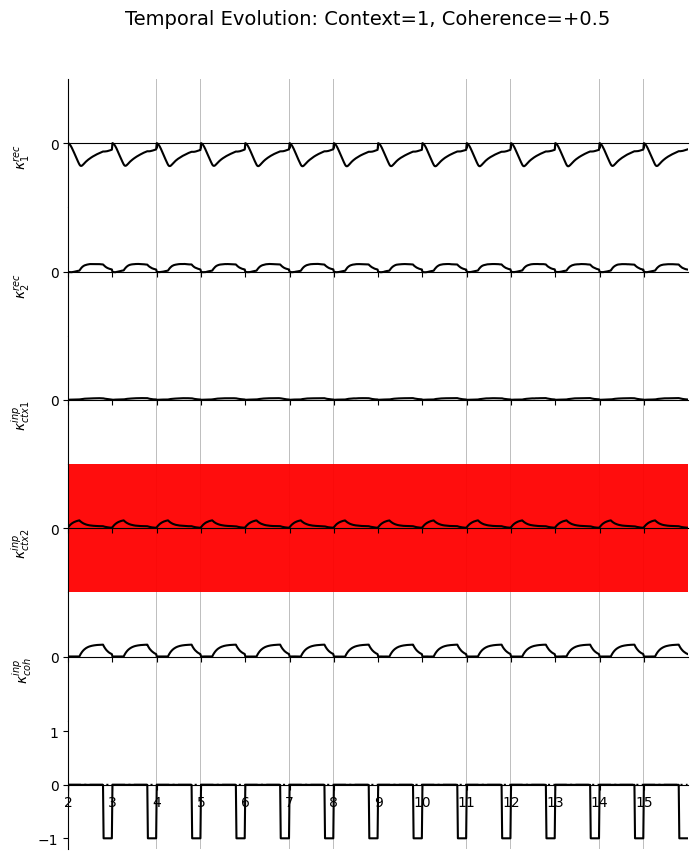

显示了trial 2到16的temporal evolution
红色背景 = Right trials, 绿色背景 = Left trials
紫色背景 = Context=1, 绿色背景 = Context=-1

=== Temporal Evolution: Context=-1, Coherence=-0.5 ===
Generating 16 trials, 75 steps per trial
Context: -1, Coherence: -0.5


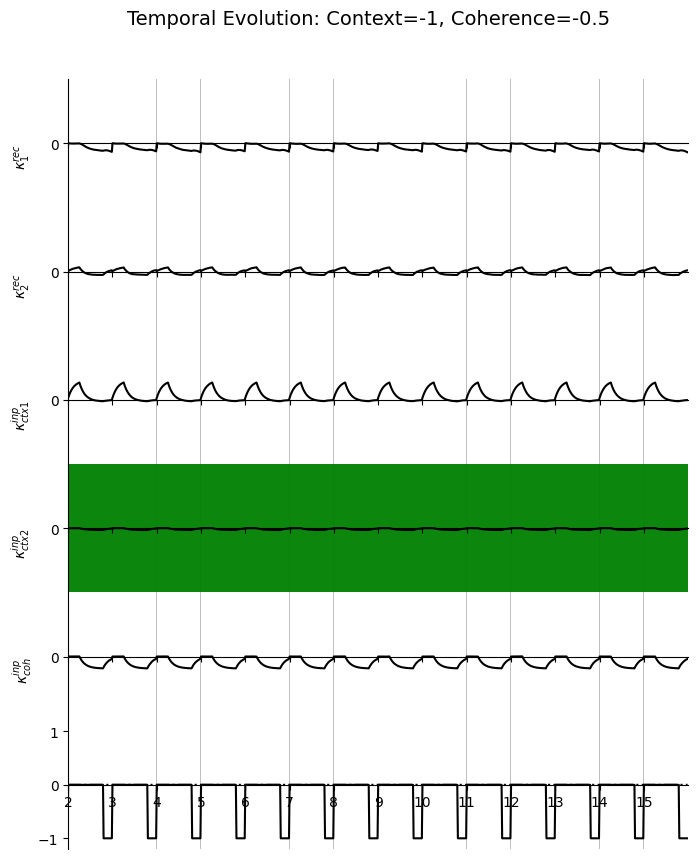

显示了trial 2到16的temporal evolution
红色背景 = Right trials, 绿色背景 = Left trials
紫色背景 = Context=1, 绿色背景 = Context=-1
=== Temporal Evolution: Context=1, Coherence=-0.5 ===
Generating 16 trials, 75 steps per trial
Context: 1, Coherence: -0.5


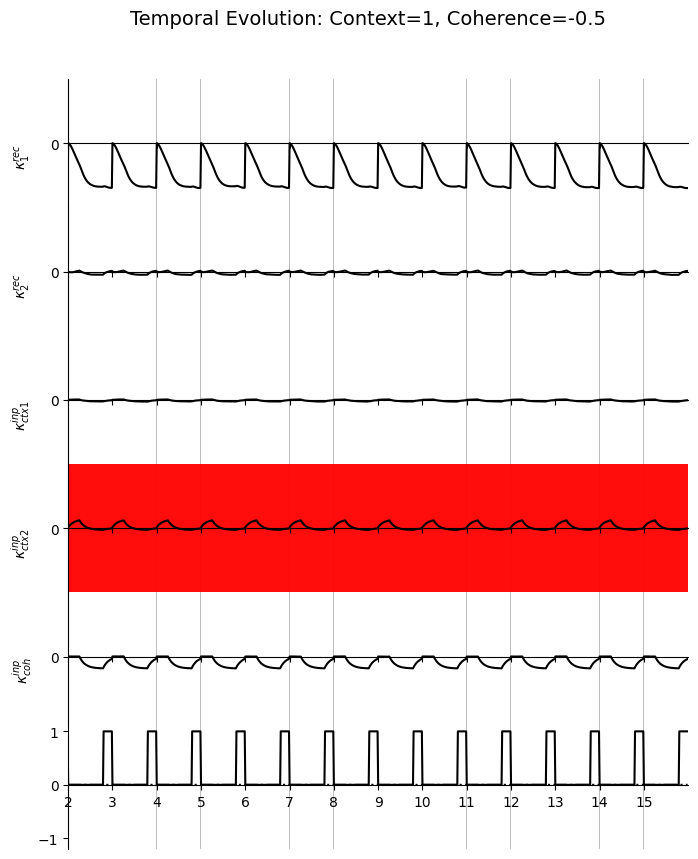

显示了trial 2到16的temporal evolution
红色背景 = Right trials, 绿色背景 = Left trials
紫色背景 = Context=1, 绿色背景 = Context=-1

=== Temporal Evolution: Context=-1, Coherence=+0.5 ===
Generating 16 trials, 75 steps per trial
Context: -1, Coherence: 0.5


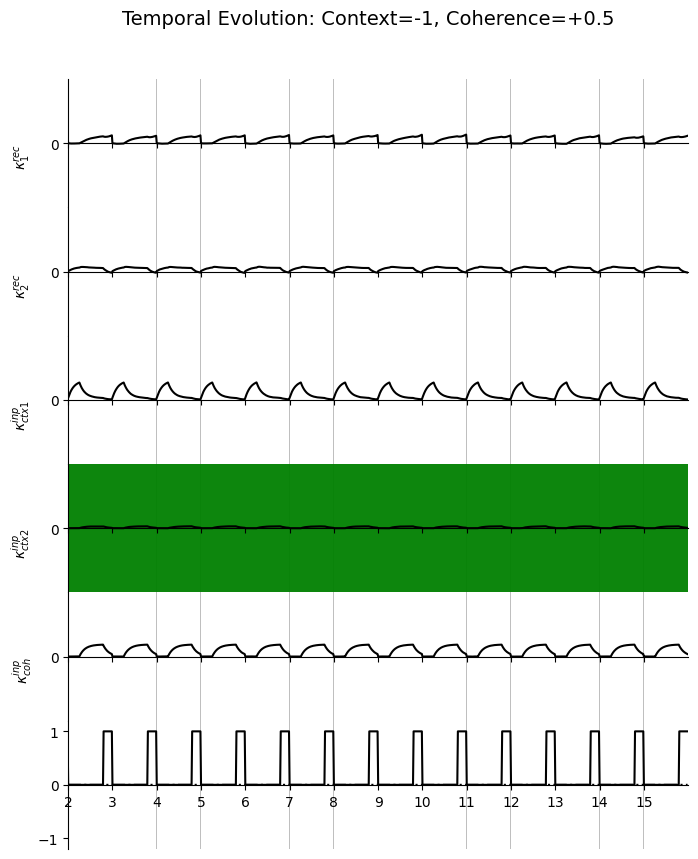

显示了trial 2到16的temporal evolution
红色背景 = Right trials, 绿色背景 = Left trials
紫色背景 = Context=1, 绿色背景 = Context=-1


In [ ]:
def plot_temporal_evolution_xor_style(net, n_trials=20, context=1, coherence=0.5, 
                                      deltaT=20, figsize=(8, 10)):
    
    
    t_ctx_steps = int(400 / deltaT)    # 20 steps
    t_stim_steps = int(800 / deltaT)   # 40 steps  
    t_dec_steps = int(300 / deltaT)    # 15 steps
    steps_per_trial = t_ctx_steps + t_stim_steps + t_dec_steps  # 75 steps per trial
    
    print(f"Generating {n_trials} trials, {steps_per_trial} steps per trial")
    print(f"Context: {context}, Coherence: {coherence}")
    
    kappa_long = []
    inputs_long = [] 
    actions_long = []
    trial_outcomes = []
    
    for trial in range(n_trials):
      
        x, y_true, _ = make_single_xor_trial(context, coherence, std=0.01)
        
        
        kappas, kappainput, _ = compute_kappas_from_net(net, x.unsqueeze(0) if x.ndim==2 else x)
        
        trial_len = min(steps_per_trial, kappas.shape[1])
        k1 = kappas[0, :trial_len, 0]
        k2 = kappas[0, :trial_len, 1]
        
        if kappainput.shape[2] > 2:
            input_coh = kappainput[0, :trial_len, 2]
        else:
            input_coh = np.zeros(trial_len)
            
        if kappainput.shape[2] > 0:
            input_ctx1 = kappainput[0, :trial_len, 0]  # context channel 1
        else:
            input_ctx1 = np.zeros(trial_len)
            
        if kappainput.shape[2] > 1:
            input_ctx2 = kappainput[0, :trial_len, 1]  # context channel 2
        else:
            input_ctx2 = np.zeros(trial_len)
        
        # Action
        action = y_true[0, :trial_len, 0].numpy()
        
        final_action = np.mean(action[-5:]) 
        trial_outcomes.append(final_action > 0)
        
       
        kappa_long.append(np.column_stack([k1, k2, input_ctx1, input_ctx2, input_coh]))
        actions_long.append(action)
    
  
    kappa_long = np.vstack(kappa_long)  # shape: (n_trials*steps_per_trial, 5)
    actions_long = np.concatenate(actions_long)  # shape: (n_trials*steps_per_trial,)
    
   
    labels = [r'$\kappa_1^{rec}$', r'$\kappa_2^{rec}$', 
             r'$\kappa^{inp}_{ctx1}$', r'$\kappa^{inp}_{ctx2}$', r'$\kappa^{inp}_{coh}$', 'action']
    
    inp_dim = 3  
    rank = 2     
    
    
    fig, ax = plt.subplots(inp_dim + rank + 1, 1, 
                          figsize=figsize, sharex=True)
    
    cm = 'black'
    
    idxs, idxe = 2, min(18, n_trials)  
    
    
    for ik in range(inp_dim + rank):
        ax[ik].plot(np.arange(n_trials * steps_per_trial), 
                   kappa_long[:, ik].flatten(), 
                   color=cm, lw=1.5, alpha=1)
        ax[ik].set_xlim([idxs * steps_per_trial, n_trials * steps_per_trial])
        
        for i in range(0, n_trials * steps_per_trial, steps_per_trial):
            ax[ik].axvspan(i + steps_per_trial - 1, i + steps_per_trial, 
                          facecolor='gray', alpha=0.5)
        
        ax[ik].spines['top'].set_visible(False)
        ax[ik].spines['right'].set_visible(False)
        ax[ik].spines['left'].set_position(('data', idxs * steps_per_trial))
        ax[ik].spines['bottom'].set_position(('data', 0))
    
    
    # for i in range(n_trials - 1):
    #     if trial_outcomes[i]:  # Right choice
    #         ccolor = 'red'
    #         alpha = 0.15
    #     else:  # Left choice
    #         ccolor = 'green' 
    #         alpha = 0.15
    #     ax[rank].axvspan((i + 1) * steps_per_trial, (i + 2) * steps_per_trial, 
    #                     facecolor=ccolor, alpha=alpha)
    
    for i in range(0, n_trials * steps_per_trial + steps_per_trial, steps_per_trial):
        if context == 1:
            ccolor = 'red'
        else:
            ccolor = 'green'
        
        if abs(coherence) > 0.1:
            transp = 0.95
        else:
            transp = 0.25
            
        ax[rank + 1].axvspan(i - steps_per_trial, i, 
                            facecolor=ccolor, alpha=transp)
    
    ax[-1].plot(np.arange(n_trials * steps_per_trial), actions_long.flatten(), 
               color=cm, lw=1.5, alpha=1)
    ax[-1].plot(np.arange(n_trials * steps_per_trial), 
               np.zeros_like(actions_long.flatten()), 
               color=cm, lw=1.5, linestyle='-.', alpha=1)
    
    for ik in range(inp_dim + rank):
        ax[ik].set_ylabel(labels[ik], fontsize=10, rotation=90, 
                         labelpad=20, va='center', ha='right')
    
    ax[rank - 1].set_xticks(np.arange(0, n_trials * steps_per_trial, steps_per_trial))
    ax[rank - 1].set_xticklabels(np.arange(0, n_trials, 1), minor=False, rotation=45)
    ax[rank - 1].set_xlim([idxs * steps_per_trial, idxe * steps_per_trial])
    
    fig.subplots_adjust(hspace=0)
    
    for i in range(0, n_trials * steps_per_trial, steps_per_trial):
        ax[-1].axvspan(i + steps_per_trial - 1, i + steps_per_trial, 
                      facecolor='gray', alpha=0.5)
    
    ax[-1].spines['top'].set_visible(False)
    ax[-1].spines['right'].set_visible(False)
    ax[-1].spines['left'].set_position(('data', idxs * steps_per_trial))
    ax[-1].spines['bottom'].set_position(('data', 0))
    
    rec_y = 0.003  
    for ir in range(rank):
        ax[ir].set_ylim([-rec_y, rec_y])
        ax[ir].set_yticks([0])
    
    for idx in range(rank, rank + inp_dim - 1):
        ax[idx].set_ylim([-0.01, 0.01])
        ax[idx].set_yticks([0])
    
    ax[rank + inp_dim - 1].set_ylim([-0.02, 0.02])
    ax[rank + inp_dim - 1].set_yticks([0])
    
    ax[-1].set_ylim([-1.2, 1.2])
    ax[-1].set_yticks([-1, 0, 1])
    
    plt.suptitle(f'Temporal Evolution: Context={context}, Coherence={coherence:+.1f}', 
                fontsize=14, y=0.95)
    plt.show()
    
    print(f"显示了trial {idxs}到{idxe}的temporal evolution")
    print(f"红色背景 = Right trials, 绿色背景 = Left trials")
    print(f"紫色背景 = Context=1, 绿色背景 = Context=-1")

#  Context=1, 正coherence
print("=== Temporal Evolution: Context=1, Coherence=+0.5 ===")
plot_temporal_evolution_xor_style(net, n_trials=16, context=1, coherence=0.5)

#  Context=-1, 负coherence  
print("\n=== Temporal Evolution: Context=-1, Coherence=-0.5 ===")
plot_temporal_evolution_xor_style(net, n_trials=16, context=-1, coherence=-0.5)

# Context=1, 负coherence
print("=== Temporal Evolution: Context=1, Coherence=-0.5 ===")
plot_temporal_evolution_xor_style(net, n_trials=16, context=1, coherence=-0.5)

# Context=-1, 正coherence  
print("\n=== Temporal Evolution: Context=-1, Coherence=+0.5 ===")
plot_temporal_evolution_xor_style(net, n_trials=16, context=-1, coherence=+0.5)

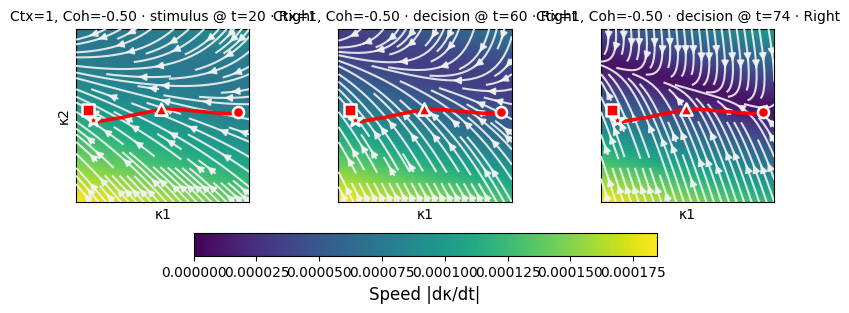

In [ ]:

target_ctx, target_coh = 1, -0.5   

flowfield_config = {
    'num_grid': 60,
    'sampleStep': [20, 60, 74],     
}
USE_TASK_INPUT   = True   
USE_TRIAL_STABLE = True   

x_trial, y_trial, _ = make_single_xor_trial(target_ctx, target_coh, std=0.0)
x_trial_b = x_trial if x_trial.ndim == 3 else x_trial.unsqueeze(0)
k_traj, v_traj, _ = compute_kappas_from_net(net, x_trial_b, normalize_by_paper=True)   # (1,T,r), (1,T,Nin)

k1 = k_traj[0, :, 0]                     
k2 = k_traj[0, :, 1]
v_s = v_traj[0].T                        

# 
with torch.no_grad():
    pred, _ = net(x_trial_b, return_dynamics=True)   # pred: (1,T,1)
action_ts     = pred[0, :, 0].detach().cpu().numpy()
decision_beg  = int(t_ctx_steps + t_stim_steps)
final_action  = float(np.mean(action_ts[decision_beg:]))
traj_color    = 'red' if final_action > 0 else 'green'
traj_ls       = '-'   if target_ctx == 1 else '--'
choice_str    = "Right" if final_action > 0 else "Left"


M      = m_univ.detach().cpu().numpy()          # (H, r)
Iin    = wi_univ.detach().cpu().numpy().T       # (H, Nin)
N_T    = net.n_univ.detach().cpu().numpy()[:, :M.shape[1]].T   # (r, H)
H, r   = M.shape
Nin    = Iin.shape[1]
alpha_lr = float(getattr(net, "alpha", 0.1))

xspan = float(k1.max() - k1.min() + 1e-12)
yspan = float(k2.max() - k2.min() + 1e-12)
cx = float(0.5*(k1.max() + k1.min()))
cy = float(0.5*(k2.max() + k2.min()))
span   = max(xspan, yspan) * 1.15
xrange = (cx - span/2, cx + span/2)
yrange = (cy - span/2, cy + span/2)

dims         = [0, 1]
rank_dim     = r
stable_dims  = np.setdiff1d(np.arange(rank_dim), dims)
Ttot         = k_traj.shape[1]
kappa_s      = k_traj[0, :, stable_dims].T if len(stable_dims)>0 else np.zeros((0, Ttot))  # (S,T)

num_grid = flowfield_config['num_grid']
xx, yy = np.meshgrid(np.linspace(*xrange, num_grid), np.linspace(*yrange, num_grid))
hidden_grid_2d = np.vstack((xx.flatten(), yy.flatten())).T

steps = flowfield_config['sampleStep']
fig, ax = plt.subplots(1, len(steps), figsize=(len(steps)*2.6, 3), sharex=True, sharey=True,
                       layout="constrained", gridspec_kw={'wspace':0.06, 'hspace':0.06})
if not isinstance(ax, (list, np.ndarray)):
    ax = [ax]

for si_idx, t_cur in enumerate(steps):
    t_cur   = int(np.clip(t_cur, 0, Ttot-1))
    t_minus = int(np.clip(t_cur-1, 0, Ttot-1))

    velocity = np.zeros((hidden_grid_2d.shape[0], rank_dim))

    for i in range(hidden_grid_2d.shape[0]):
        kappa_t = np.zeros((rank_dim, 1))
        kappa_t[dims, 0] = hidden_grid_2d[i, :]
        if len(stable_dims) > 0:
            kappa_t[stable_dims, 0] = kappa_s[:, t_minus]
        v_t = v_s[:, t_cur].reshape(-1, 1) if USE_TASK_INPUT else np.zeros((Nin, 1))

        
        x_t   = M @ kappa_t + Iin @ v_t
        phi_x = np.tanh(x_t)

        # κ_{t+1} = (1-α) κ_t + α * (N^T φ(x_t)) / H
        delta_k   = (N_T @ phi_x) / float(H)
        kappa_tp1 = (1.0 - alpha_lr) * kappa_t + alpha_lr * delta_k

        velocity[i, :] = (kappa_tp1 - kappa_t).ravel()

    U = velocity[:, dims[0]].reshape(num_grid, num_grid)
    V = velocity[:, dims[1]].reshape(num_grid, num_grid)
    speed = np.sqrt(U**2 + V**2)
    vmax = float(np.max(speed)); vmax = vmax if vmax>1e-12 else 1e-12

    cax = ax[si_idx].pcolormesh(xx, yy, speed, cmap='viridis', zorder=-20, alpha=1, vmin=0, vmax=vmax)

    Um, Vm = U.copy(), V.copy()
    mask = (speed < 1e-6 * vmax)
    Um[mask] = np.nan; Vm[mask] = np.nan
    ax[si_idx].streamplot(xx, yy, Um, Vm, zorder=20, color=[0.95,0.95,0.95,0.9], density=0.8)

    ax[si_idx].plot(k1, k2, color=traj_color, linestyle=traj_ls, linewidth=2.6, alpha=0.95, zorder=30)
    ax[si_idx].scatter(k1[0], k2[0], marker='o', s=64, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    if t_ctx_steps < len(k1):
        ax[si_idx].scatter(k1[t_ctx_steps], k2[t_ctx_steps], marker='^', s=76, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    if decision_beg < len(k1):
        ax[si_idx].scatter(k1[decision_beg], k2[decision_beg], marker='*', s=100, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    ax[si_idx].scatter(k1[-1], k2[-1], marker='s', s=76, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)

    ax[si_idx].set_aspect('equal', adjustable='box')
    ax[si_idx].set_xlim(xrange); ax[si_idx].set_ylim(yrange)
    ax[si_idx].set_xticks([]); ax[si_idx].set_yticks([])
    ax[si_idx].set_xlabel('κ1')
    if si_idx == 0: ax[si_idx].set_ylabel('κ2')
    phase = "context" if t_cur < t_ctx_steps else ("stimulus" if t_cur < t_ctx_steps + t_stim_steps else "decision")
    ax[si_idx].set_title(f"Ctx={target_ctx}, Coh={target_coh:+.2f} · {phase} @ t={t_cur} · {choice_str}", fontsize=10)

cbar = fig.colorbar(cax, ax=ax if isinstance(ax, (list, np.ndarray)) else [ax], orientation='horizontal', shrink=0.6)
cbar.set_label('Speed |dκ/dt|', fontsize=12)
cbar.ax.tick_params(labelsize=10)
plt.show()


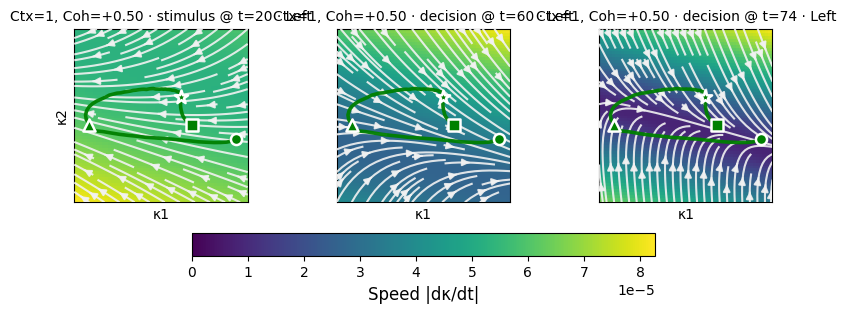

In [ ]:

target_ctx, target_coh = 1, 0.5    

flowfield_config = {
    'num_grid': 60,
    'sampleStep': [20, 60, 74],     
}
USE_TASK_INPUT   = True   
USE_TRIAL_STABLE = True   

）
x_trial, y_trial, _ = make_single_xor_trial(target_ctx, target_coh, std=0.0)
x_trial_b = x_trial if x_trial.ndim == 3 else x_trial.unsqueeze(0)
k_traj, v_traj, _ = compute_kappas_from_net(net, x_trial_b, normalize_by_paper=True)   # (1,T,r), (1,T,Nin)

k1 = k_traj[0, :, 0]                     
k2 = k_traj[0, :, 1]
v_s = v_traj[0].T                        


with torch.no_grad():
    pred, _ = net(x_trial_b, return_dynamics=True)   # pred: (1,T,1)
action_ts     = pred[0, :, 0].detach().cpu().numpy()
decision_beg  = int(t_ctx_steps + t_stim_steps)
final_action  = float(np.mean(action_ts[decision_beg:]))
traj_color    = 'red' if final_action > 0 else 'green'
traj_ls       = '-'   if target_ctx == 1 else '--'
choice_str    = "Right" if final_action > 0 else "Left"


M      = m_univ.detach().cpu().numpy()          # (H, r)
Iin    = wi_univ.detach().cpu().numpy().T       # (H, Nin)
N_T    = net.n_univ.detach().cpu().numpy()[:, :M.shape[1]].T   # (r, H)
H, r   = M.shape
Nin    = Iin.shape[1]
alpha_lr = float(getattr(net, "alpha", 0.1))


xspan = float(k1.max() - k1.min() + 1e-12)
yspan = float(k2.max() - k2.min() + 1e-12)
cx = float(0.5*(k1.max() + k1.min()))
cy = float(0.5*(k2.max() + k2.min()))
span   = max(xspan, yspan) * 1.15
xrange = (cx - span/2, cx + span/2)
yrange = (cy - span/2, cy + span/2)


dims         = [0, 1]
rank_dim     = r
stable_dims  = np.setdiff1d(np.arange(rank_dim), dims)
Ttot         = k_traj.shape[1]
kappa_s      = k_traj[0, :, stable_dims].T if len(stable_dims)>0 else np.zeros((0, Ttot))  # (S,T)

num_grid = flowfield_config['num_grid']
xx, yy = np.meshgrid(np.linspace(*xrange, num_grid), np.linspace(*yrange, num_grid))
hidden_grid_2d = np.vstack((xx.flatten(), yy.flatten())).T


steps = flowfield_config['sampleStep']
fig, ax = plt.subplots(1, len(steps), figsize=(len(steps)*2.6, 3), sharex=True, sharey=True,
                       layout="constrained", gridspec_kw={'wspace':0.06, 'hspace':0.06})
if not isinstance(ax, (list, np.ndarray)):
    ax = [ax]

for si_idx, t_cur in enumerate(steps):
    t_cur   = int(np.clip(t_cur, 0, Ttot-1))
    t_minus = int(np.clip(t_cur-1, 0, Ttot-1))

    velocity = np.zeros((hidden_grid_2d.shape[0], rank_dim))

    for i in range(hidden_grid_2d.shape[0]):
        
        kappa_t = np.zeros((rank_dim, 1))
        kappa_t[dims, 0] = hidden_grid_2d[i, :]
        if len(stable_dims) > 0:
            kappa_t[stable_dims, 0] = kappa_s[:, t_minus]

        v_t = v_s[:, t_cur].reshape(-1, 1) if USE_TASK_INPUT else np.zeros((Nin, 1))

        
        x_t   = M @ kappa_t + Iin @ v_t
        phi_x = np.tanh(x_t)

        # κ_{t+1} = (1-α) κ_t + α * (N^T φ(x_t)) / H
        delta_k   = (N_T @ phi_x) / float(H)
        kappa_tp1 = (1.0 - alpha_lr) * kappa_t + alpha_lr * delta_k

        velocity[i, :] = (kappa_tp1 - kappa_t).ravel()

    U = velocity[:, dims[0]].reshape(num_grid, num_grid)
    V = velocity[:, dims[1]].reshape(num_grid, num_grid)
    speed = np.sqrt(U**2 + V**2)
    vmax = float(np.max(speed)); vmax = vmax if vmax>1e-12 else 1e-12

    cax = ax[si_idx].pcolormesh(xx, yy, speed, cmap='viridis', zorder=-20, alpha=1, vmin=0, vmax=vmax)

    Um, Vm = U.copy(), V.copy()
    mask = (speed < 1e-6 * vmax)
    Um[mask] = np.nan; Vm[mask] = np.nan
    ax[si_idx].streamplot(xx, yy, Um, Vm, zorder=20, color=[0.95,0.95,0.95,0.9], density=0.8)

    ax[si_idx].plot(k1, k2, color=traj_color, linestyle=traj_ls, linewidth=2.6, alpha=0.95, zorder=30)
    ax[si_idx].scatter(k1[0], k2[0], marker='o', s=64, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    if t_ctx_steps < len(k1):
        ax[si_idx].scatter(k1[t_ctx_steps], k2[t_ctx_steps], marker='^', s=76, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    if decision_beg < len(k1):
        ax[si_idx].scatter(k1[decision_beg], k2[decision_beg], marker='*', s=100, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    ax[si_idx].scatter(k1[-1], k2[-1], marker='s', s=76, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)

    ax[si_idx].set_aspect('equal', adjustable='box')
    ax[si_idx].set_xlim(xrange); ax[si_idx].set_ylim(yrange)
    ax[si_idx].set_xticks([]); ax[si_idx].set_yticks([])
    ax[si_idx].set_xlabel('κ1')
    if si_idx == 0: ax[si_idx].set_ylabel('κ2')
    phase = "context" if t_cur < t_ctx_steps else ("stimulus" if t_cur < t_ctx_steps + t_stim_steps else "decision")
    ax[si_idx].set_title(f"Ctx={target_ctx}, Coh={target_coh:+.2f} · {phase} @ t={t_cur} · {choice_str}", fontsize=10)

cbar = fig.colorbar(cax, ax=ax if isinstance(ax, (list, np.ndarray)) else [ax], orientation='horizontal', shrink=0.6)
cbar.set_label('Speed |dκ/dt|', fontsize=12)
cbar.ax.tick_params(labelsize=10)
plt.show()


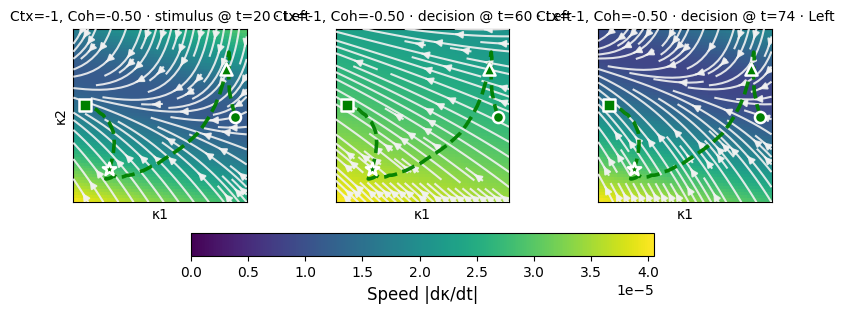

In [ ]:

target_ctx, target_coh = -1, -0.5    

flowfield_config = {
    'num_grid': 60,
    'sampleStep': [20, 60, 74],     
}
USE_TASK_INPUT   = True  
USE_TRIAL_STABLE = True   


x_trial, y_trial, _ = make_single_xor_trial(target_ctx, target_coh, std=0.0)
x_trial_b = x_trial if x_trial.ndim == 3 else x_trial.unsqueeze(0)
k_traj, v_traj, _ = compute_kappas_from_net(net, x_trial_b, normalize_by_paper=True)   # (1,T,r), (1,T,Nin)

k1 = k_traj[0, :, 0]                     
k2 = k_traj[0, :, 1]
v_s = v_traj[0].T                        # (Nin, T) 

with torch.no_grad():
    pred, _ = net(x_trial_b, return_dynamics=True)   # pred: (1,T,1)
action_ts     = pred[0, :, 0].detach().cpu().numpy()
decision_beg  = int(t_ctx_steps + t_stim_steps)
final_action  = float(np.mean(action_ts[decision_beg:]))
traj_color    = 'red' if final_action > 0 else 'green'
traj_ls       = '-'   if target_ctx == 1 else '--'
choice_str    = "Right" if final_action > 0 else "Left"

M      = m_univ.detach().cpu().numpy()          # (H, r)
Iin    = wi_univ.detach().cpu().numpy().T       # (H, Nin)
N_T    = net.n_univ.detach().cpu().numpy()[:, :M.shape[1]].T   # (r, H)
H, r   = M.shape
Nin    = Iin.shape[1]
alpha_lr = float(getattr(net, "alpha", 0.1))

xspan = float(k1.max() - k1.min() + 1e-12)
yspan = float(k2.max() - k2.min() + 1e-12)
cx = float(0.5*(k1.max() + k1.min()))
cy = float(0.5*(k2.max() + k2.min()))
span   = max(xspan, yspan) * 1.15
xrange = (cx - span/2, cx + span/2)
yrange = (cy - span/2, cy + span/2)

dims         = [0, 1]
rank_dim     = r
stable_dims  = np.setdiff1d(np.arange(rank_dim), dims)
Ttot         = k_traj.shape[1]
kappa_s      = k_traj[0, :, stable_dims].T if len(stable_dims)>0 else np.zeros((0, Ttot))  # (S,T)

num_grid = flowfield_config['num_grid']
xx, yy = np.meshgrid(np.linspace(*xrange, num_grid), np.linspace(*yrange, num_grid))
hidden_grid_2d = np.vstack((xx.flatten(), yy.flatten())).T

steps = flowfield_config['sampleStep']
fig, ax = plt.subplots(1, len(steps), figsize=(len(steps)*2.6, 3), sharex=True, sharey=True,
                       layout="constrained", gridspec_kw={'wspace':0.06, 'hspace':0.06})
if not isinstance(ax, (list, np.ndarray)):
    ax = [ax]

for si_idx, t_cur in enumerate(steps):
    t_cur   = int(np.clip(t_cur, 0, Ttot-1))
    t_minus = int(np.clip(t_cur-1, 0, Ttot-1))

    velocity = np.zeros((hidden_grid_2d.shape[0], rank_dim))

    for i in range(hidden_grid_2d.shape[0]):
       
        kappa_t = np.zeros((rank_dim, 1))
        kappa_t[dims, 0] = hidden_grid_2d[i, :]
        if len(stable_dims) > 0:
            kappa_t[stable_dims, 0] = kappa_s[:, t_minus]

        v_t = v_s[:, t_cur].reshape(-1, 1) if USE_TASK_INPUT else np.zeros((Nin, 1))

        x_t   = M @ kappa_t + Iin @ v_t
        phi_x = np.tanh(x_t)

        # κ_{t+1} = (1-α) κ_t + α * (N^T φ(x_t)) / H
        delta_k   = (N_T @ phi_x) / float(H)
        kappa_tp1 = (1.0 - alpha_lr) * kappa_t + alpha_lr * delta_k

        velocity[i, :] = (kappa_tp1 - kappa_t).ravel()

    U = velocity[:, dims[0]].reshape(num_grid, num_grid)
    V = velocity[:, dims[1]].reshape(num_grid, num_grid)
    speed = np.sqrt(U**2 + V**2)
    vmax = float(np.max(speed)); vmax = vmax if vmax>1e-12 else 1e-12

    cax = ax[si_idx].pcolormesh(xx, yy, speed, cmap='viridis', zorder=-20, alpha=1, vmin=0, vmax=vmax)

    Um, Vm = U.copy(), V.copy()
    mask = (speed < 1e-6 * vmax)
    Um[mask] = np.nan; Vm[mask] = np.nan
    ax[si_idx].streamplot(xx, yy, Um, Vm, zorder=20, color=[0.95,0.95,0.95,0.9], density=0.8)

    ax[si_idx].plot(k1, k2, color=traj_color, linestyle=traj_ls, linewidth=2.6, alpha=0.95, zorder=30)
    ax[si_idx].scatter(k1[0], k2[0], marker='o', s=64, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    if t_ctx_steps < len(k1):
        ax[si_idx].scatter(k1[t_ctx_steps], k2[t_ctx_steps], marker='^', s=76, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    if decision_beg < len(k1):
        ax[si_idx].scatter(k1[decision_beg], k2[decision_beg], marker='*', s=100, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    ax[si_idx].scatter(k1[-1], k2[-1], marker='s', s=76, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)

    ax[si_idx].set_aspect('equal', adjustable='box')
    ax[si_idx].set_xlim(xrange); ax[si_idx].set_ylim(yrange)
    ax[si_idx].set_xticks([]); ax[si_idx].set_yticks([])
    ax[si_idx].set_xlabel('κ1')
    if si_idx == 0: ax[si_idx].set_ylabel('κ2')
    phase = "context" if t_cur < t_ctx_steps else ("stimulus" if t_cur < t_ctx_steps + t_stim_steps else "decision")
    ax[si_idx].set_title(f"Ctx={target_ctx}, Coh={target_coh:+.2f} · {phase} @ t={t_cur} · {choice_str}", fontsize=10)


cbar = fig.colorbar(cax, ax=ax if isinstance(ax, (list, np.ndarray)) else [ax], orientation='horizontal', shrink=0.6)
cbar.set_label('Speed |dκ/dt|', fontsize=12)
cbar.ax.tick_params(labelsize=10)
plt.show()


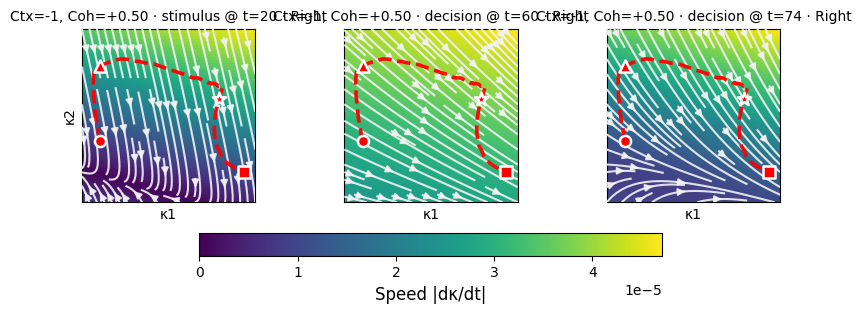

In [ ]:

target_ctx, target_coh = -1, 0.5    

flowfield_config = {
    'num_grid': 60,
    'sampleStep': [20, 60, 74],     
}
USE_TASK_INPUT   = True  
USE_TRIAL_STABLE = True   

x_trial, y_trial, _ = make_single_xor_trial(target_ctx, target_coh, std=0.0)
x_trial_b = x_trial if x_trial.ndim == 3 else x_trial.unsqueeze(0)
k_traj, v_traj, _ = compute_kappas_from_net(net, x_trial_b, normalize_by_paper=True)   # (1,T,r), (1,T,Nin)

k1 = k_traj[0, :, 0]                     
k2 = k_traj[0, :, 1]
v_s = v_traj[0].T                       

with torch.no_grad():
    pred, _ = net(x_trial_b, return_dynamics=True)   # pred: (1,T,1)
action_ts     = pred[0, :, 0].detach().cpu().numpy()
decision_beg  = int(t_ctx_steps + t_stim_steps)
final_action  = float(np.mean(action_ts[decision_beg:]))
traj_color    = 'red' if final_action > 0 else 'green'
traj_ls       = '-'   if target_ctx == 1 else '--'
choice_str    = "Right" if final_action > 0 else "Left"

M      = m_univ.detach().cpu().numpy()          # (H, r)
Iin    = wi_univ.detach().cpu().numpy().T       # (H, Nin)
N_T    = net.n_univ.detach().cpu().numpy()[:, :M.shape[1]].T   # (r, H)
H, r   = M.shape
Nin    = Iin.shape[1]
alpha_lr = float(getattr(net, "alpha", 0.1))

xspan = float(k1.max() - k1.min() + 1e-12)
yspan = float(k2.max() - k2.min() + 1e-12)
cx = float(0.5*(k1.max() + k1.min()))
cy = float(0.5*(k2.max() + k2.min()))
span   = max(xspan, yspan) * 1.15
xrange = (cx - span/2, cx + span/2)
yrange = (cy - span/2, cy + span/2)

dims         = [0, 1]
rank_dim     = r
stable_dims  = np.setdiff1d(np.arange(rank_dim), dims)
Ttot         = k_traj.shape[1]
kappa_s      = k_traj[0, :, stable_dims].T if len(stable_dims)>0 else np.zeros((0, Ttot))  # (S,T)

num_grid = flowfield_config['num_grid']
xx, yy = np.meshgrid(np.linspace(*xrange, num_grid), np.linspace(*yrange, num_grid))
hidden_grid_2d = np.vstack((xx.flatten(), yy.flatten())).T

steps = flowfield_config['sampleStep']
fig, ax = plt.subplots(1, len(steps), figsize=(len(steps)*2.6, 3), sharex=True, sharey=True,
                       layout="constrained", gridspec_kw={'wspace':0.06, 'hspace':0.06})
if not isinstance(ax, (list, np.ndarray)):
    ax = [ax]

for si_idx, t_cur in enumerate(steps):
    t_cur   = int(np.clip(t_cur, 0, Ttot-1))
    t_minus = int(np.clip(t_cur-1, 0, Ttot-1))

    velocity = np.zeros((hidden_grid_2d.shape[0], rank_dim))

    for i in range(hidden_grid_2d.shape[0]):
        kappa_t = np.zeros((rank_dim, 1))
        kappa_t[dims, 0] = hidden_grid_2d[i, :]
        if len(stable_dims) > 0:
            kappa_t[stable_dims, 0] = kappa_s[:, t_minus]

        v_t = v_s[:, t_cur].reshape(-1, 1) if USE_TASK_INPUT else np.zeros((Nin, 1))

        
        x_t   = M @ kappa_t + Iin @ v_t
        phi_x = np.tanh(x_t)

        # κ_{t+1} = (1-α) κ_t + α * (N^T φ(x_t)) / H
        delta_k   = (N_T @ phi_x) / float(H)
        kappa_tp1 = (1.0 - alpha_lr) * kappa_t + alpha_lr * delta_k

        velocity[i, :] = (kappa_tp1 - kappa_t).ravel()

    U = velocity[:, dims[0]].reshape(num_grid, num_grid)
    V = velocity[:, dims[1]].reshape(num_grid, num_grid)
    speed = np.sqrt(U**2 + V**2)
    vmax = float(np.max(speed)); vmax = vmax if vmax>1e-12 else 1e-12

    cax = ax[si_idx].pcolormesh(xx, yy, speed, cmap='viridis', zorder=-20, alpha=1, vmin=0, vmax=vmax)

    Um, Vm = U.copy(), V.copy()
    mask = (speed < 1e-6 * vmax)
    Um[mask] = np.nan; Vm[mask] = np.nan
    ax[si_idx].streamplot(xx, yy, Um, Vm, zorder=20, color=[0.95,0.95,0.95,0.9], density=0.8)

    ax[si_idx].plot(k1, k2, color=traj_color, linestyle=traj_ls, linewidth=2.6, alpha=0.95, zorder=30)
    ax[si_idx].scatter(k1[0], k2[0], marker='o', s=64, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    if t_ctx_steps < len(k1):
        ax[si_idx].scatter(k1[t_ctx_steps], k2[t_ctx_steps], marker='^', s=76, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    if decision_beg < len(k1):
        ax[si_idx].scatter(k1[decision_beg], k2[decision_beg], marker='*', s=100, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)
    ax[si_idx].scatter(k1[-1], k2[-1], marker='s', s=76, color=traj_color, edgecolor='white', linewidth=1.8, zorder=35)

    ax[si_idx].set_aspect('equal', adjustable='box')
    ax[si_idx].set_xlim(xrange); ax[si_idx].set_ylim(yrange)
    ax[si_idx].set_xticks([]); ax[si_idx].set_yticks([])
    ax[si_idx].set_xlabel('κ1')
    if si_idx == 0: ax[si_idx].set_ylabel('κ2')
    phase = "context" if t_cur < t_ctx_steps else ("stimulus" if t_cur < t_ctx_steps + t_stim_steps else "decision")
    ax[si_idx].set_title(f"Ctx={target_ctx}, Coh={target_coh:+.2f} · {phase} @ t={t_cur} · {choice_str}", fontsize=10)

cbar = fig.colorbar(cax, ax=ax if isinstance(ax, (list, np.ndarray)) else [ax], orientation='horizontal', shrink=0.6)
cbar.set_label('Speed |dκ/dt|', fontsize=12)
cbar.ax.tick_params(labelsize=10)
plt.show()
